# Token forcing vs temperature in an LLM program search for TSP heuristics (NOV-T demo)

**The question.** Raising the sampling temperature is the usual "creativity knob" of an LLM-driven program search.
NOV-T tests a targeted alternative: **decision-token branching (DTB)**. DTB forces a rank-2..8 token at the
*highest-entropy code position* among the first 48 generated body tokens, then lets the model continue at T = 1.
The claim under test (V2-T) is that DTB discovers more *distinct heuristic behaviours* per LLM call than
temperature does.

**Setup.**
- **Task.** Constructive TSP with the ReEvo/EoH interface
  `select_next_node(current_node, destination_node, unvisited_nodes, distance_matrix)`.
- **Model and search.** Qwen3-8B-FP8 (vLLM 0.11, thinking off) mutates programs in a FunSearch-style search with
  5 islands, all seeded with nearest neighbour (**NN**).
- **Fitness.** F = 0.5·G50/G50(NN) + 0.5·G100/G100(NN), where Gn is the mean gap to LKH-3 tours on the 64
  SELECTION instances of size n (32 at n = 50, 32 at n = 100). NN scores F = 1; lower is better.
- **Arms**, compared at matched calls in interleaved rounds:
  - **T1.0**: temperature 1, top-p 1.
  - **T1.6**: temperature 1.6, top-p 0.95.
  - **DTB**: the forcing described above.
  - **RPB**: the same forcing at a *random* eligible position (the placebo).
  - **IDEA**: an instruction to use a different idea.
  - **NOSEL**: no selection (a comparator).
- **Behaviour instrument.** Each program's next-city decisions on 2,000 frozen probe states. Programs are grouped
  by complete-linkage clustering, and every cluster has within-cluster agreement ≥ 0.95. **V2-T compares behaviour
  clusters per 1,000 calls.**

**Full-run result** (10,812 calls; seeds 0 and 1; 1,056 calls per arm and seed):
- **V2-T is DISCONFIRMED** by the pre-registered rule. Clusters per 1,000 calls, seed 0 / seed 1: T1.0 228 / 234,
  T1.6 88 / 104, DTB 228 / 217, RPB 237 / 233, IDEA 296 / 298. The pooled DTB/T1.0 ratio is 0.963.
  DTB does branch where intended (median entropy at the forced position ≈ 0.8 nats, against ≈ 0 for RPB), but the
  forced token adds no behavioural diversity beyond T1.0 or a random-position forcing. The *instruction* arm IDEA
  gives the most clusters.
- **V1-T is SUPPORTED.** Every core arm's best program closes at least 20% of NN's held-out gap.

**What this notebook re-runs.** The LLM calls need a GPU and a vLLM server, so the notebook **replays the logged
completions** of 100 matched calls: seed 0, 20 calls per arm for T1.0, T1.6, DTB, RPB and IDEA, taken from rounds
0, 8, 16, 24 and 32. Everything downstream of the LLM is re-run on CPU with the original code, and every step is
checked against the values logged in the original run:
- prompt construction and program extraction;
- the fork-per-program sandbox on the SELECTION instances and the 2,000 probe states;
- the FunSearch islands database;
- the DTB/RPB forcing, re-derived from the logged top-20 log-probabilities;
- behaviour clustering, ratios and the bootstrap;
- the held-out check and the verdict rules.

The LKH-3 reference tour lengths are loaded from the data (the original run computed them with `elkai`).

## 1. Setup
The code uses numpy, scipy and matplotlib, plus `transformers` for the Qwen3 tokenizer (DTB/RPB re-derivation and
prompt token counts; no model weights are downloaded). All of them are pre-installed on Colab. Locally, the cell
installs Colab's exact versions.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# numpy, scipy, matplotlib, transformers, tokenizers, huggingface_hub — pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0',
         'transformers==5.0.0', 'tokenizers==0.22.2', 'huggingface_hub==1.4.0')

The import block merges the imports of the original modules `common.py`, `tsp_task.py`, `probes.py`,
`sandbox.py`, `prompt.py`, `islands.py`, `dtb.py`, `analysis.py` and `analyze_run.py`. As in `common.py`, the
thread limits are set before numpy is imported.

In [2]:
from __future__ import annotations

import os

# common.py: every evaluator / numeric process must be single-threaded
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")  # prompt.py; the sandbox forks after the tokenizer is used

import ast
import builtins
import hashlib
import json
import keyword
import math
import pickle
import random
import re
import resource
import select
import signal
import struct
import sys
import time
import warnings
from collections import Counter, defaultdict
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
import scipy.special
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial import distance_matrix as _scipy_dm
from scipy.spatial.distance import pdist, squareform  # squareform: notebook visualisation only

import matplotlib.pyplot as plt

# The sandbox forks one child per program from this multi-threaded kernel (the original forked from a spawned
# evaluator process); Python 3.12 warns about fork() in threaded processes.
warnings.filterwarnings("ignore", message=r".*use of fork\(\) may lead to deadlocks.*", category=DeprecationWarning)
# numpy RuntimeWarnings raised inside candidate programs (e.g. divide by zero) went to the evaluator's own stderr
warnings.filterwarnings("ignore", category=RuntimeWarning, module="candidate")

### Data
`mini_demo_data.json` is a 100-call subset of the `novt_calls` dataset (one row per LLM call) from the run's
`full_method_out.json`. Each row keeps the published fields: arm, call index, label, F, the generated program
body and the DTB fields. It adds the fields that let the notebook re-run the pipeline:
- the island, the parents and the 64 logged SELECTION gaps;
- the logged 2,000 probe decisions;
- for DTB/RPB calls, the logged request-1 token ids and top-20 log-probabilities at all 48 positions.

The top-level `metadata` holds the LKH-3 reference lengths, the NN baseline and the full-run headline numbers.

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-10/experiment-53/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
META = data["metadata"]
EX = data["datasets"][0]["examples"]
ARMS = ["T1.0", "T1.6", "DTB", "RPB", "IDEA"]  # analyze_run.py ARMS (NOSEL is not in the demo subset)

print(f"dataset {data['datasets'][0]['dataset']!r}: {len(EX)} logged LLM calls")
for a in ARMS:
    labs = Counter(e["metadata_label"] for e in EX if e["metadata_arm"] == a)
    print(f"  {a:5s} {sum(labs.values())} calls: " + ", ".join(f"{k} {v}" for k, v in labs.most_common()))
print("\nexample row:", EX[0]["input"], "->", EX[0]["output"])
print(EX[0]["metadata_body"])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
dataset 'novt_calls': 100 logged LLM calls
  T1.0  20 calls: valid 12, invalid_return 7, runtime_error 1
  T1.6  20 calls: invalid_return 11, valid 7, runtime_error 2
  DTB   20 calls: valid 14, runtime_error 3, invalid_return 3
  RPB   20 calls: valid 9, runtime_error 7, invalid_return 3, import_violation 1
  IDEA  20 calls: valid 14, runtime_error 3, invalid_return 3

example row: arm=T1.0 seed=0 call=0 round=0 island=4 k=1 parents=NN parent_F=1.0000 -> valid|1.678710
    next_node = None
    best_score = float("inf")
    
    for node in unvisited_nodes:
        # Calculate a combined score: distance to current node + distance from node to destination
        score = distance_matrix[current_node][node] + distance_matrix[node][destination_node]
        if score < best_score:
            best_score = score
            next_node = node
            
    return next_node



## 2. Configuration
The demo-scale knobs are below. The full-run values are in the comments. At full fidelity (32 + 32 SELECTION
instances and all 2,000 probe states), the re-evaluation reproduces the logged rows exactly, and the analysis then
uses the re-computed values. At smaller values it re-checks a prefix, and the analysis falls back to the logged
rows.

In [5]:
N_CALLS_PER_ARM = 20   # calls per arm re-evaluated in the sandbox (data: 20 matched calls per arm; full run: 1,056 per arm-seed)
N_SEL_PER_SIZE = 32    # SELECTION instances per size, n = 50 and n = 100 (original: 32 + 32 = 64)
N_PROBE_STATES = 2000  # probe states per program (original: 2,000 — the behaviour instrument)
N_HELDOUT = 32         # HELDOUT n = 200 instances for each arm's selection-best program (original: 32; EXT 96 + TSPLIB 13 not run here)
N_DTB_REDERIVE = 40    # DTB/RPB calls whose forcing is re-derived from logged top-20 log probs (data: 40; audit test: 50)
N_BOOT = 1000          # paired round-block bootstrap resamples (original: 1,000)
N_RAREFY = 1000        # rarefaction subsamples (original: 1,000)
SEEDS_DEMO = [0]       # the demo data hold seed 0 (original: seeds 0 and 1)

## 3. The pipeline (`method.py`)
`method.py` is the entry point. `python method.py <stage>` runs each stage as its own process, and long stages
run in the background with checkpoints. The GPU stages (`gpu`, `pilot`, `search`) need the vLLM server
(`bash start_vllm.sh compile`).

```
stage0   hardware, instances, probe states, TSPLIB, LKH-3 references, NN gate, baselines
p1       tuned parametric baseline P1: 2,000-evaluation random search (rng 777)
tests    CPU unit tests T1-T9          gpu      GPU mechanics tests G1-G5 + throughput probe
commit1  predictions/protocol.json, hash-chained in commitments.log (before the first search call)
pilot    seed 99, 10 calls per arm     search   the main search (reads data/targets.json every round)
commit2  C* from the measured round times (COMMIT #2)      corpus   published-heuristic corpus (COMMIT #3)
analyze  clusters, rarefaction, bootstrap, held-out bests, verdicts -> results/*.json
judges   V3-T candidates -> gated OpenRouter judges        figures  F1..F6
outputs  method_out.json + full/mini/preview               rederive audit/rederive.py (stdlib re-derivation)
```

Below is the stage table from `method.py`, together with what this notebook does with each stage.

In [6]:
# method.py (original)
PY = sys.executable
STAGES = {
    "stage0": [PY, "src/stage0.py", "all"],
    "p1": [PY, "src/p1_search.py", "2"],
    "tests": [PY, "-m", "pytest", "-q", "-c", "tests/pytest.ini", "--rootdir", ".", "tests/test_core.py",
              "-p", "no:cacheprovider"],
    "gpu": [PY, "tests/gpu_mechanics.py"],
    "commit1": [PY, "src/commit.py", "commit1"],
    "pilot": [PY, "src/search.py", "--out", "data/pilot", "--n-eval", "4"],
    "search": [PY, "src/search.py", "--out", "data", "--n-eval", "4", "--wait"],
    "commit2": [PY, "src/cstar.py"],
    "corpus": [PY, "src/corpus.py"],
    "analyze": [PY, "src/analyze_run.py"],
    "judges": [PY, "src/judges.py"],
    "figures": [PY, "src/figures.py"],
    "outputs": [PY, "src/outputs.py"],
    "rederive": [PY, "audit/rederive.py"],
}
# Notebook: no subprocesses; the CPU parts of these stages run in-process on the logged LLM completions.
IN_THIS_NOTEBOOK = {
    "stage0": "sections 4-7: instances, probe states, NN gate (LKH-3 lengths loaded)",
    "search": "sections 8-10: prompts, extraction, sandbox, islands, DTB/RPB (LLM replayed)",
    "analyze": "sections 12-13: clusters, rarefaction, bootstrap, held-out, verdicts",
    "rederive": "section 11: forcing re-derived from logged top-20 log probs",
}
for name, cmd in STAGES.items():
    print(f"{name:9s} {' '.join(cmd[1:])[:44]:44s} -> {IN_THIS_NOTEBOOK.get(name, 'not run in this demo')}")

stage0    src/stage0.py all                            -> sections 4-7: instances, probe states, NN gate (LKH-3 lengths loaded)
p1        src/p1_search.py 2                           -> not run in this demo
tests     -m pytest -q -c tests/pytest.ini --rootdir . -> not run in this demo
gpu       tests/gpu_mechanics.py                       -> not run in this demo
commit1   src/commit.py commit1                        -> not run in this demo
pilot     src/search.py --out data/pilot --n-eval 4    -> not run in this demo
search    src/search.py --out data --n-eval 4 --wait   -> sections 8-10: prompts, extraction, sandbox, islands, DTB/RPB (LLM replayed)
commit2   src/cstar.py                                 -> not run in this demo
corpus    src/corpus.py                                -> not run in this demo
analyze   src/analyze_run.py                           -> sections 12-13: clusters, rarefaction, bootstrap, held-out, verdicts
judges    src/judges.py                                ->

## 4. Shared helpers and the TSP task (`common.py`, `tsp_task.py`)
The instances are uniform random points in the unit square, drawn from fixed seeds. SELECTION (32 × n = 50 plus
32 × n = 100) is the only set the search ever sees. HELDOUT (32 × n = 200) scores the best program of each arm.
The runtime files the notebook writes go to `./novt_demo_run/`: the probe-state cache and the empty sandbox
working directories.

In [7]:
# common.py (paths re-rooted for the notebook)
ROOT = Path.cwd() / "novt_demo_run"
DATA = ROOT / "data"
DATA.mkdir(parents=True, exist_ok=True)


def sha256_bytes(b: bytes) -> str:
    return hashlib.sha256(b).hexdigest()


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()

In [8]:
# tsp_task.py: instance sets (seed, n). SELECTION is the only set the search ever sees.
SETS: dict[str, list[tuple[int, int]]] = {
    "selection": [(910001 + i, 50) for i in range(32)] + [(910101 + i, 100) for i in range(32)],
    "heldout": [(920001 + i, 200) for i in range(32)],
    "heldout_ext": [(920033 + i, 200) for i in range(96)],
    "probe": [(930001 + i, int(round(50 + 150 * i / 19))) for i in range(20)],
}


def coords_for(seed: int, n: int) -> np.ndarray:
    return np.random.default_rng(seed).uniform(0, 1, (n, 2))


def dist_matrix(coords: np.ndarray) -> np.ndarray:
    return _scipy_dm(coords, coords).astype(np.float64)


def tour_length(tour, D: np.ndarray) -> float:
    t = np.asarray(tour, dtype=np.int64)
    return float(D[t, np.roll(t, -1)].sum())


# evaluator.load_references(): the LKH-3 reference length of every instance. The original solved each instance with
# elkai (tsp_task.solve_reference: 10 runs on round(D * 1e6)) into data/references.jsonl; the demo loads those
# lengths from the data.
def load_references() -> dict[str, np.ndarray]:
    out = {}
    for name, rs in META["references"].items():
        assert [r["seed"] for r in rs] == [s for s, _ in SETS[name]], name
        out[name] = np.array([r["L_ref"] for r in rs])
    return out


REFS = load_references()
# demo subsets (config): the first N_SEL_PER_SIZE instances of each SELECTION size and the first N_HELDOUT held-out
SEL_IDX = list(range(N_SEL_PER_SIZE)) + list(range(32, 32 + N_SEL_PER_SIZE))
REF_SEL, REF_HELD = REFS["selection"][SEL_IDX], REFS["heldout"][:N_HELDOUT]
print({k: len(v) for k, v in REFS.items()}, "reference lengths loaded; the demo uses", len(REF_SEL),
      "SELECTION and", len(REF_HELD), "HELDOUT instances")

{'selection': 64, 'heldout': 32} reference lengths loaded; the demo uses 64 SELECTION and 32 HELDOUT instances


## 5. The seed program and the frozen probe states (`baselines.py`, `probes.py`)
Every island starts from the nearest-neighbour program **NN**, which scores F = 1 by construction. Two further
baselines are not re-run here: the tuned parametric rule P1 (a 2,000-evaluation random search) and the
insertion/greedy-edge references.

The **behaviour instrument** is fixed before the search starts. Each of the 20 probe instances (n from 50 to 200)
gets an NN tour and a random-insertion tour. From each tour, 50 prefix lengths t are drawn, and each prefix defines
a state (current city, unvisited set). A program's behaviour is its vector of 2,000 next-city decisions. The cell
rebuilds these states from their seeds and checks that they are identical to the run's frozen states.

In [9]:
# baselines.py: the NN seed program
NN_PROGRAM = '''import numpy as np
import math


def select_next_node(current_node, destination_node, unvisited_nodes, distance_matrix):
    """Return the next city to visit: one element of unvisited_nodes."""
    next_node = None
    best_distance = float("inf")
    for node in unvisited_nodes:
        distance = distance_matrix[current_node][node]
        if distance < best_distance:
            best_distance = distance
            next_node = node
    return next_node
'''

In [10]:
# probes.py
PROBES_RULE = """Frozen probe states for the name-blind behaviour instrument (frozen before COMMIT #1).

For each of the 20 PROBE instances (n_i = round(50 + 150 i/19)): an NN tour and a random-insertion tour
(rng 930100+i), each read in visiting order from city 0. From each tour, 50 prefix lengths t ~ U{1..n-2} are
drawn without replacement (one generator, rng 930200+i, NN tour first). When n-2 < 50 (only i = 0, n = 50: 48
values) all 48 values are taken and the remaining 2 are drawn with replacement (logged deviation).
State = (instance i, current = tour[t-1], destination 0, unvisited = all cities not in tour[:t]).
"""
PROBE_STATES_PATH = DATA / "probe_states.json"
N_PER_TOUR = 50


def nn_tour(D: np.ndarray) -> list[int]:
    n = len(D)
    tour, U = [0], np.ones(n, dtype=bool)
    U[0] = False
    cur = 0
    for _ in range(n - 1):
        d = np.where(U, D[cur], np.inf)
        nxt = int(np.argmin(d))
        tour.append(nxt)
        U[nxt] = False
        cur = nxt
    return tour


def random_insertion_tour(D: np.ndarray, rng: np.random.Generator) -> list[int]:
    """Random insertion: cities in random order, each inserted where it lengthens the tour least."""
    n = len(D)
    order = list(rng.permutation(n))
    tour = order[:2]
    for c in order[2:]:
        t = np.asarray(tour)
        nxt = np.roll(t, -1)
        inc = D[t, c] + D[c, nxt] - D[t, nxt]
        k = int(np.argmin(inc))
        tour.insert(k + 1, int(c))
    i0 = tour.index(0)
    return [int(x) for x in tour[i0:] + tour[:i0]]


def _prefix_lengths(rng: np.random.Generator, n: int) -> tuple[list[int], bool]:
    pool = np.arange(1, n - 1)  # 1..n-2
    if len(pool) >= N_PER_TOUR:
        return [int(x) for x in rng.choice(pool, size=N_PER_TOUR, replace=False)], False
    first = [int(x) for x in rng.permutation(pool)]
    extra = [int(x) for x in rng.choice(pool, size=N_PER_TOUR - len(first), replace=True)]
    return first + extra, True


def build_probe_states() -> dict:
    """Returns {'states': [(inst, cur, unvisited_list)], 'meta': [...], 'n': [...], 'sha256': ...}."""
    if PROBE_STATES_PATH.exists():
        obj = json.loads(PROBE_STATES_PATH.read_text())
        obj["sha256"] = sha256_file(PROBE_STATES_PATH)
        return obj
    states, meta, padded = [], [], []
    for i, (seed, n) in enumerate(SETS["probe"]):
        D = dist_matrix(coords_for(seed, n))
        tours = {"nn": nn_tour(D), "ri": random_insertion_tour(D, np.random.default_rng(930100 + i))}
        rng = np.random.default_rng(930200 + i)
        for kind in ("nn", "ri"):
            tour = tours[kind]
            assert tour[0] == 0 and sorted(tour) == list(range(n))
            ts, pad = _prefix_lengths(rng, n)
            if pad:
                padded.append({"instance": i, "tour": kind, "n": n})
            for t in ts:
                prefix = tour[:t]
                unv = sorted(set(range(n)) - set(prefix))
                states.append([i, int(tour[t - 1]), unv])
                meta.append({"instance": i, "tour": kind, "t": t, "n": n})
    obj = {"states": states, "meta": meta, "n": [n for _, n in SETS["probe"]], "padded": padded,
           "rule": PROBES_RULE}  # original: the module docstring
    PROBE_STATES_PATH.write_text(json.dumps(obj))
    obj["sha256"] = sha256_file(PROBE_STATES_PATH)
    return obj


def probe_matrices() -> list[np.ndarray]:
    return [dist_matrix(coords_for(seed, n)) for seed, n in SETS["probe"]]


def agreement(a: np.ndarray, b: np.ndarray) -> float:
    """Share of probe states with the same decision (ERR = -1 only matches -1)."""
    return float(np.mean(np.asarray(a) == np.asarray(b)))


pst = build_probe_states()
print(f"{len(pst['states'])} probe states on {len(pst['n'])} instances (n = {pst['n'][0]}..{pst['n'][-1]}); "
      f"padded: {pst['padded']}")
print("identical to the run's frozen probe states:",
      sha256_text(json.dumps(pst["states"])) == META["probe_states_sha256"])

2000 probe states on 20 instances (n = 50..200); padded: [{'instance': 0, 'tour': 'nn', 'n': 50}, {'instance': 0, 'tour': 'ri', 'n': 50}]
identical to the run's frozen probe states: True


## 6. The sandbox (`sandbox.py`)
Generated programs are untrusted. Each program goes through two steps.
1. **Static AST check.** Only whitelisted imports are allowed. Forbidden names (`open`, `exec`, `os`, …) and
   dunder attributes are rejected. Top-level statements other than imports, definitions and constant assignments
   are stripped.
2. **Fork-per-program execution.** The program runs in a child process with CPU, address-space and file-size
   limits, restricted builtins and a guarded `__import__`. The program is re-executed fresh for every instance and
   every probe call. Each call receives a fresh `set` copy and a fresh writable distance-matrix copy (ReEvo
   semantics).

The **AST hash** (docstrings stripped; comments never reach the AST) identifies a program. The search caches
evaluations by this hash.

In [11]:
# sandbox.py (1/2): static check and AST hash
ALLOWED_IMPORTS = {"numpy", "math", "random", "heapq", "itertools", "collections", "functools", "typing", "bisect"}
FORBIDDEN_NAMES = {"open", "exec", "eval", "compile", "__import__", "globals", "locals", "vars", "input",
                   "breakpoint", "exit", "quit", "help", "memoryview", "__builtins__", "__loader__", "__spec__"}
FORBIDDEN_MODULE_NAMES = {"os", "sys", "subprocess", "socket", "importlib", "builtins", "shutil", "pathlib",
                          "ctypes", "multiprocessing", "threading", "signal", "resource", "gc", "inspect"}
SAFE_CALLS_IN_CONST = {"float", "int", "abs", "round", "tuple", "list", "dict", "set", "frozenset", "range",
                       "min", "max", "pow", "complex", "bool", "str", "len", "sum"}
ERROR_CLASSES = ["no_code", "syntax_error", "import_violation", "runtime_error", "invalid_return", "timeout",
                 "truncated"]
FUNC = "select_next_node"
SEL_CPU = 30          # s CPU for the 64 SELECTION instances together
PROBE_CPU = 30        # s CPU for the 2,000 probe calls
HARD_CPU = 62         # hard RLIMIT_CPU of the combined child
WALL_FACTOR = 1.5     # parent wall limit = 1.5 x CPU limit (per phase)
SET_CPU = 600         # s CPU per HELDOUT / EXT / TSPLIB set
MEM_LIMIT = 2 * 1024 ** 3
PROBE_ERR_MAX = 0.10  # PROBE-VALID requires at most 10% ERR decisions
ERR = -1


class StaticReject(Exception):
    def __init__(self, cls: str, reason: str):
        super().__init__(reason)
        self.cls, self.reason = cls, reason


def _is_const_expr(node: ast.AST) -> bool:
    for sub in ast.walk(node):
        if isinstance(sub, ast.Call):
            f = sub.func
            ok = (isinstance(f, ast.Name) and f.id in SAFE_CALLS_IN_CONST) or (
                isinstance(f, ast.Attribute) and isinstance(f.value, ast.Name) and f.value.id in ("np", "math", "numpy"))
            if not ok:
                return False
        elif isinstance(sub, (ast.Lambda, ast.ListComp, ast.SetComp, ast.DictComp, ast.GeneratorExp, ast.Await,
                              ast.Yield, ast.YieldFrom, ast.NamedExpr)):
            return False
    return True


def static_check(code: str) -> str:
    """Return sanitised source (top level: imports, defs, constant assignments) or raise StaticReject."""
    try:
        tree = ast.parse(code)
    except SyntaxError as e:
        raise StaticReject("syntax_error", f"{e.msg} line {e.lineno}") from None
    keep = []
    for node in tree.body:
        if isinstance(node, (ast.Import, ast.ImportFrom)):
            names = [a.name for a in node.names] if isinstance(node, ast.Import) else [node.module or ""]
            for nm in names:
                if nm.split(".")[0] not in ALLOWED_IMPORTS or (isinstance(node, ast.ImportFrom) and node.level):
                    raise StaticReject("import_violation", f"import {nm}")
            keep.append(node)
        elif isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
            keep.append(node)
        elif isinstance(node, (ast.Assign, ast.AnnAssign)) and node.value is not None:
            tg = node.targets if isinstance(node, ast.Assign) else [node.target]
            if all(isinstance(t, (ast.Name, ast.Tuple)) for t in tg) and _is_const_expr(node.value):
                keep.append(node)
        # every other top-level statement (prints, tests, loops, if __name__ ...) is stripped
    for sub in ast.walk(ast.Module(body=keep, type_ignores=[])):
        if isinstance(sub, (ast.Import, ast.ImportFrom)):
            names = [a.name for a in sub.names] if isinstance(sub, ast.Import) else [sub.module or ""]
            for nm in names:
                if nm.split(".")[0] not in ALLOWED_IMPORTS or (isinstance(sub, ast.ImportFrom) and sub.level):
                    raise StaticReject("import_violation", f"import {nm}")
        elif isinstance(sub, ast.Name):
            if sub.id in FORBIDDEN_NAMES or sub.id in FORBIDDEN_MODULE_NAMES:
                raise StaticReject("import_violation", f"forbidden name {sub.id}")
        elif isinstance(sub, ast.Attribute):
            if sub.attr.startswith("__") and sub.attr not in ("__name__", "__init__", "__len__", "__lt__",
                                                              "__eq__", "__hash__", "__repr__", "__iter__"):
                raise StaticReject("import_violation", f"dunder attribute {sub.attr}")
        elif isinstance(sub, ast.Call) and isinstance(sub.func, ast.Name) and sub.func.id in ("getattr", "setattr",
                                                                                            "delattr", "hasattr"):
            for a in sub.args[1:2]:
                if not (isinstance(a, ast.Constant) and isinstance(a.value, str) and not a.value.startswith("_")):
                    raise StaticReject("import_violation", f"{sub.func.id} with non-literal/dunder name")
    if not any(isinstance(n, ast.FunctionDef) and n.name == FUNC for n in keep):
        raise StaticReject("no_code", f"no {FUNC} defined")
    return ast.unparse(ast.Module(body=keep, type_ignores=[]))


def strip_docstrings(tree: ast.AST) -> ast.AST:
    for node in ast.walk(tree):
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef, ast.Module)):
            b = node.body
            if b and isinstance(b[0], ast.Expr) and isinstance(b[0].value, ast.Constant) and isinstance(
                    b[0].value.value, str):
                node.body = b[1:] or [ast.Pass()]
    return tree


def ast_hash(code: str) -> str | None:
    """sha256 of the AST dump with docstrings stripped (comments never reach the AST)."""
    try:
        tree = ast.parse(code)
    except SyntaxError:
        return None
    return hashlib.sha256(ast.dump(strip_docstrings(tree), annotate_fields=False).encode()).hexdigest()


# illustration: NN passes; a program that imports os is rejected before anything runs
for src in (NN_PROGRAM, "import os\ndef select_next_node(a, b, c, d):\n    return os.getpid()\n"):
    try:
        print("accepted, ast_hash", ast_hash(static_check(src))[:16], "...")
    except StaticReject as e:
        print("rejected:", e.cls, "-", e.reason)

accepted, ast_hash 3b474372ccb1c126 ...
rejected: import_violation - import os


Execution side: `fork_eval` forks one child per program. The child sets `RLIMIT_CPU`, `RLIMIT_AS` and
`RLIMIT_FSIZE`, then runs the phases in order (SELECTION tours, then the probe decisions) and sends each phase's
result back through a length-prefixed pickle frame. The parent enforces a wall limit of 1.5 × the CPU limit per
phase.

The code below differs from the original in two places, both marked *notebook fix*:
- **Sandbox directory.** The sandbox's empty working directory lives under `ROOT`.
- **Address-space limit.** The original evaluator was a small spawned process. Here the child is forked from the
  Jupyter kernel, which already maps several GB of address space, so the 2 GB `RLIMIT_AS` budget is added on top
  of the kernel's current size.

In [12]:
# sandbox.py (2/2): child-side execution and the fork server
_SBX = {"dir": None}


def _sbx_dir() -> str:
    """An empty working directory per evaluator process, created BEFORE the child's RLIMIT_FSIZE 0 (inside the
    workspace: scratch/sbx/<pid>); the child cannot write files there (FSIZE 0, no open/os)."""
    if _SBX["dir"] is None or not os.path.isdir(_SBX["dir"]):
        root = os.path.join(str(ROOT), "scratch", "sbx", str(os.getpid()))  # notebook fix: ROOT instead of src/..
        os.makedirs(root, exist_ok=True)
        _SBX["dir"] = root
    return _SBX["dir"]


def _vm_bytes() -> int:
    """Notebook fix: the address space this process already maps (VmSize)."""
    with open("/proc/self/status") as f:
        for line in f:
            if line.startswith("VmSize:"):
                return int(line.split()[1]) * 1024
    return 0


class CpuLimit(BaseException):
    """Raised from the SIGXCPU handler; BaseException so candidate `except Exception` cannot swallow it."""


def _on_xcpu(signum, frame):  # noqa: ARG001
    raise CpuLimit()


def _guarded_import(name, globals=None, locals=None, fromlist=(), level=0):
    if level != 0 or name.split(".")[0] not in ALLOWED_IMPORTS:
        raise ImportError(f"import of {name} is not allowed")
    return builtins.__import__(name, globals, locals, fromlist, level)


def _safe_builtins() -> dict:
    sb = {k: getattr(builtins, k) for k in dir(builtins) if k not in FORBIDDEN_NAMES and not k.startswith("_")}
    sb["__import__"] = _guarded_import
    sb["__build_class__"] = builtins.__build_class__
    sb["__name__"] = "candidate"
    return sb


class InvalidReturn(Exception):
    pass


def _fresh_fn(code_obj):
    ns = {"__builtins__": _safe_builtins(), "__name__": "candidate"}
    exec(code_obj, ns)
    fn = ns.get(FUNC)
    if not callable(fn):
        raise InvalidReturn(f"{FUNC} not callable")
    return fn


def _as_city(x, U: set) -> int:
    """Accept ints, numpy ints and integral floats that are in the unvisited set."""
    if isinstance(x, (bool, np.bool_)) or x is None:
        raise InvalidReturn(f"returned {x!r}")
    if isinstance(x, (int, np.integer)):
        v = int(x)
    elif isinstance(x, (float, np.floating)):
        if not np.isfinite(x) or float(x) != int(x):
            raise InvalidReturn(f"non-integer {x!r}")
        v = int(x)
    elif isinstance(x, np.ndarray) and x.ndim == 0 and np.issubdtype(x.dtype, np.integer):
        v = int(x)
    else:
        raise InvalidReturn(f"returned type {type(x).__name__}")
    if v not in U:
        raise InvalidReturn(f"returned {v} not in unvisited")
    return v


def run_tours(code_obj, mats, seeds, tours_out: list | None = None) -> list[float]:
    """Build closed tours from city 0 on each instance (ReEvo protocol); returns lengths (raises on any failure).

    Every call gets a fresh set copy and a fresh writable matrix copy; np.random / random are seeded once per
    instance with the instance seed; the program is exec'd fresh per instance.
    """
    out = []
    for D, sd in zip(mats, seeds):
        fn = _fresh_fn(code_obj)
        n = D.shape[0]
        np.random.seed(sd % (2 ** 32))
        random.seed(sd)
        cur, tour, U = 0, [0], set(range(1, n))
        for _ in range(n - 1):
            nxt = _as_city(fn(cur, 0, set(U), D.copy()), U)
            tour.append(nxt)
            U.remove(nxt)
            cur = nxt
        t = np.asarray(tour)
        out.append(float(D[t, np.roll(t, -1)].sum()))
        if tours_out is not None:
            tours_out.append(tour)
    return out


def run_probes(code_obj, states, mats) -> list[int]:
    """One decision per probe state; ERR (-1) = exception or invalid return. Fresh exec per call; RNGs seeded
    with 930000+k before every call."""
    dec = []
    for k, (inst, cur, unv) in enumerate(states):
        try:
            fn = _fresh_fn(code_obj)
            np.random.seed((930000 + k) % (2 ** 32))
            random.seed(930000 + k)
            U = set(unv)
            dec.append(_as_city(fn(cur, 0, set(U), mats[inst].copy()), U))
        except Exception:  # noqa: BLE001 - any ordinary failure of the candidate is an ERR decision
            dec.append(ERR)
    return dec


def _send(wfd: int, obj) -> None:
    data = pickle.dumps(obj)
    os.write(wfd, struct.pack("<Q", len(data)))
    view, off = memoryview(data), 0
    while off < len(data):
        off += os.write(wfd, view[off:off + (1 << 20)])


def _classify(e: BaseException, phase: str) -> dict:
    if isinstance(e, CpuLimit):
        return {"ok": False, "cls": "probe_timeout" if phase == "probe" else "timeout", "reason": "cpu soft limit"}
    if isinstance(e, InvalidReturn):
        return {"ok": False, "cls": "invalid_return", "reason": str(e)[:300]}
    if isinstance(e, MemoryError):
        return {"ok": False, "cls": "runtime_error", "reason": f"MemoryError {e}"[:300]}
    if isinstance(e, ImportError):
        return {"ok": False, "cls": "import_violation", "reason": str(e)[:300]}
    if isinstance(e, RecursionError):
        return {"ok": False, "cls": "runtime_error", "reason": f"RecursionError {e}"[:300]}
    return {"ok": False, "cls": "runtime_error", "reason": f"{type(e).__name__}: {e}"[:300]}


def _child(wfd: int, code: str, jobs: list, cpu_soft: int, cpu_hard: int, extra_cpu: list) -> None:
    """jobs: list of (phase, mode, payload). Each phase's result is sent as its own frame; the first failure stops."""
    try:
        resource.setrlimit(resource.RLIMIT_CPU, (cpu_soft, cpu_hard))
        mem = MEM_LIMIT + _vm_bytes()  # notebook fix: 2 GB on top of what the forked kernel already maps
        resource.setrlimit(resource.RLIMIT_AS, (mem, mem))
        resource.setrlimit(resource.RLIMIT_FSIZE, (0, 0))
        signal.signal(signal.SIGXCPU, _on_xcpu)
        try:
            os.nice(5)
        except OSError:
            pass
        os.chdir(_sbx_dir())
        code_obj = compile(code, "<candidate>", "exec")
    except BaseException as e:  # noqa: BLE001
        _send(wfd, {"phase": jobs[0][0], **_classify(e, jobs[0][0])})
        os._exit(0)
    for j, (phase, mode, payload) in enumerate(jobs):
        try:
            if j > 0:
                used = resource.getrusage(resource.RUSAGE_SELF)
                used_s = used.ru_utime + used.ru_stime
                soft = min(int(used_s) + 1 + extra_cpu[j], cpu_hard)
                resource.setrlimit(resource.RLIMIT_CPU, (soft, cpu_hard))
            t0 = time.process_time()
            if mode == "tours":
                mats, seeds = payload[0], payload[1]
                want = len(payload) > 2 and payload[2]
                tours: list = []
                res = {"ok": True, "lengths": run_tours(code_obj, mats, seeds, tours if want else None)}
                if want:
                    res["tours"] = tours
            elif mode == "probes":
                states, mats = payload
                res = {"ok": True, "decisions": run_probes(code_obj, states, mats)}
            else:
                raise ValueError(mode)
            res["cpu"] = time.process_time() - t0
            res["phase"] = phase
        except BaseException as e:  # noqa: BLE001 - candidate code may raise anything
            res = {"phase": phase, **_classify(e, phase)}
        try:
            _send(wfd, res)
        except BaseException:  # noqa: BLE001
            os._exit(0)
        if not res.get("ok"):
            break
    os._exit(0)


def fork_eval(code: str, jobs: list, cpu_limits: list[int], cpu_hard: int | None = None) -> list[dict]:
    """Fork one child that runs `code` over `jobs` (phase, mode, payload) in order.

    cpu_limits[j] is the CPU budget of phase j (the soft limit is raised before every later phase);
    the parent's wall limit for phase j is WALL_FACTOR x cpu_limits[j]. Returns one dict per phase reached.
    """
    cpu_hard = cpu_hard or (sum(cpu_limits) + 2)
    _sbx_dir()
    rfd, wfd = os.pipe()
    pid = os.fork()
    if pid == 0:
        os.close(rfd)
        try:
            _child(wfd, code, jobs, cpu_limits[0], cpu_hard, cpu_limits)
        finally:
            os._exit(0)
    os.close(wfd)
    results: list[dict] = []
    buf = b""
    phase_idx = 0
    t_phase = time.time()
    deadline = t_phase + WALL_FACTOR * cpu_limits[0] + 2
    killed = False
    eof = False
    while not eof and phase_idx < len(jobs):
        left = deadline - time.time()
        if left <= 0:
            os.kill(pid, signal.SIGKILL)
            killed = True
            break
        r, _, _ = select.select([rfd], [], [], min(left, 1.0))
        if not r:
            continue
        b = os.read(rfd, 1 << 20)
        if not b:
            eof = True
        buf += b
        while len(buf) >= 8:
            (ln,) = struct.unpack("<Q", buf[:8])
            if len(buf) < 8 + ln:
                break
            res = pickle.loads(buf[8:8 + ln])
            buf = buf[8 + ln:]
            res["wall"] = time.time() - t_phase
            results.append(res)
            phase_idx += 1
            t_phase = time.time()
            if phase_idx < len(jobs):
                deadline = t_phase + WALL_FACTOR * cpu_limits[phase_idx] + 2
            if not res.get("ok"):
                phase_idx = len(jobs)
    os.close(rfd)
    _, status = os.waitpid(pid, 0)
    if len(results) < len(jobs) and (not results or results[-1].get("ok")):
        phase = jobs[len(results)][0]
        tcls = "probe_timeout" if phase == "probe" else "timeout"
        if killed:
            results.append({"ok": False, "cls": tcls, "reason": "wall limit", "phase": phase})
        elif os.WIFSIGNALED(status) and os.WTERMSIG(status) in (signal.SIGXCPU, signal.SIGKILL):
            results.append({"ok": False, "cls": tcls, "reason": f"cpu limit (signal {os.WTERMSIG(status)})",
                            "phase": phase})
        else:
            sig = os.WTERMSIG(status) if os.WIFSIGNALED(status) else None
            results.append({"ok": False, "cls": "runtime_error", "reason": f"child died (signal {sig})",
                            "phase": phase})
    return results


# ------------------------------------------------------------------ evaluator worker state
_W: dict = {}


def worker_init(sets_payload: dict) -> None:
    """sets_payload: {'selection': (mats, seeds), 'heldout': ..., 'probe_states': [...], 'probe_mats': [...]}.

    Matrices stay writable: every candidate call receives its own D.copy(), so in-place writes cannot leak.
    """
    os.environ["OMP_NUM_THREADS"] = "1"
    _W.update(sets_payload)
    _sbx_dir()


def evaluate_program(raw_program: str, with_probes: bool = True) -> dict:
    """Static check + SELECTION (+ PROBES in the same child). Returns a dict with label, lengths, decisions."""
    try:
        code = static_check(raw_program)
    except StaticReject as e:
        return {"label": e.cls, "reason": e.reason, "lengths": None, "decisions": None, "probe_label": None,
                "cpu_sel": 0.0, "cpu_probe": 0.0, "wall": 0.0}
    jobs = [("selection", "tours", _W["selection"])]
    limits = [SEL_CPU]
    if with_probes:
        jobs.append(("probe", "probes", (_W["probe_states"], _W["probe_mats"])))
        limits.append(PROBE_CPU)
    t0 = time.time()
    res = fork_eval(code, jobs, limits, cpu_hard=HARD_CPU if with_probes else SEL_CPU + 2)
    out = {"label": None, "reason": None, "lengths": None, "decisions": None, "probe_label": None,
           "cpu_sel": None, "cpu_probe": None, "wall": time.time() - t0}
    r0 = res[0]
    if not r0.get("ok"):
        out.update(label=r0["cls"], reason=r0.get("reason"), cpu_sel=r0.get("cpu"))
        return out
    out.update(label="valid", lengths=r0["lengths"], cpu_sel=r0.get("cpu"))
    if with_probes:
        r1 = res[1] if len(res) > 1 else {"ok": False, "cls": "probe_timeout", "reason": "missing"}
        if r1.get("ok"):
            dec = r1["decisions"]
            n_err = sum(1 for d in dec if d == ERR)
            out.update(decisions=dec, cpu_probe=r1.get("cpu"), n_err=n_err,
                       probe_label="probe_valid" if n_err <= PROBE_ERR_MAX * len(dec) else "probe_err")
        else:
            out.update(probe_label=r1.get("cls", "probe_error"), reason=r1.get("reason"))
    return out


def evaluate_set(raw_program: str, set_name: str, cpu_limit: int = SET_CPU) -> dict:
    """Tours on a held-out set (HELDOUT / EXT / TSPLIB) in one child with `cpu_limit` seconds of CPU."""
    try:
        code = static_check(raw_program)
    except StaticReject as e:
        return {"label": e.cls, "reason": e.reason, "lengths": None}
    res = fork_eval(code, [(set_name, "tours", _W[set_name])], [cpu_limit])[0]
    if res.get("ok"):
        return {"label": "valid", "lengths": res["lengths"], "tours": res.get("tours"), "cpu": res.get("cpu"),
                "wall": res.get("wall")}
    return {"label": res["cls"], "reason": res.get("reason"), "lengths": None}


def probe_program(raw_program: str, cpu_limit: int = PROBE_CPU) -> dict:
    try:
        code = static_check(raw_program)
    except StaticReject as e:
        return {"label": e.cls, "decisions": None}
    res = fork_eval(code, [("probe", "probes", (_W["probe_states"], _W["probe_mats"]))], [cpu_limit])[0]
    if res.get("ok"):
        return {"label": "ok", "decisions": res["decisions"], "cpu": res.get("cpu")}
    return {"label": res["cls"], "reason": res.get("reason"), "decisions": None}

## 7. Evaluator payload, gaps and fitness (`evaluator.py`) and the NN gate
Each spawned evaluator worker of the original holds the matrices of every instance set and the probe states. The
notebook builds this payload once, in-process, for the demo subsets.

The gap of a tour is 100·(L − L_LKH)/L_LKH. Fitness F normalises the mean SELECTION gaps by NN's, so F(NN) = 1.
Stage 0's NN gate runs NN through the same sandbox. Its gaps and probe decisions must equal the run's.

In [13]:
# evaluator.py
def load_payload() -> dict:
    """Matrices and per-instance RNG seeds of every set, plus the frozen probe states.

    Demo: SELECTION / HELDOUT subsets from the config, no HELDOUT_EXT or TSPLIB; the coordinates come straight from
    tsp_task.coords_for (the original cached them in data/instances/*.npz via tsp_task.build_sets)."""
    payload = {}
    sel = [SETS["selection"][i] for i in SEL_IDX]
    payload["selection"] = ([dist_matrix(coords_for(s, n)) for s, n in sel], [s for s, _ in sel])
    held = SETS["heldout"][:N_HELDOUT]
    payload["heldout"] = ([dist_matrix(coords_for(s, n)) for s, n in held], [s for s, _ in held])
    payload["probe_states"] = [(int(i), int(c), list(u)) for i, c, u in pst["states"][:N_PROBE_STATES]]
    payload["probe_mats"] = probe_matrices()
    return payload


worker_init(load_payload())  # evaluator._init() in every spawned worker of the original pool


def gaps_from_lengths(lengths, L_ref: np.ndarray) -> np.ndarray:
    L = np.asarray(lengths, dtype=np.float64)
    return 100.0 * (L - L_ref) / L_ref


def fitness(gaps64: np.ndarray, nn_g50: float, nn_g100: float) -> tuple[float, float, float]:
    """F = 0.5 G50/G50(NN) + 0.5 G100/G100(NN); lower is better, NN = 1."""
    g50 = float(np.mean(gaps64[:N_SEL_PER_SIZE]))                     # original: gaps64[:32]
    g100 = float(np.mean(gaps64[N_SEL_PER_SIZE:2 * N_SEL_PER_SIZE]))  # original: gaps64[32:64]
    return 0.5 * g50 / nn_g50 + 0.5 * g100 / nn_g100, g50, g100

In [14]:
# stage 0, NN gate: NN through the same sandbox -> G50 / G100 (the normalisers of F) and NN's probe decisions
t0 = time.time()
nn_res = evaluate_program(NN_PROGRAM, with_probes=True)
nn_gaps = gaps_from_lengths(nn_res["lengths"], REF_SEL)
NN_G50, NN_G100 = float(nn_gaps[:N_SEL_PER_SIZE].mean()), float(nn_gaps[N_SEL_PER_SIZE:].mean())
NN_DEC = np.array(nn_res["decisions"])
nn_dec_logged = np.array([b if b != 255 else ERR for b in bytes.fromhex(META["NN"]["probe_decisions_hex"])])
print(f"NN: {nn_res['label']}, {nn_res['probe_label']}, {time.time() - t0:.1f}s "
      f"(sandbox CPU: SELECTION {nn_res['cpu_sel']:.2f}s, probes {nn_res['cpu_probe']:.2f}s)")
print(f"G50(NN) = {NN_G50:.4f}, G100(NN) = {NN_G100:.4f} on the demo subset "
      f"(full run, 32 + 32 instances: {META['NN']['G50']:.4f} / {META['NN']['G100']:.4f})")
print("per-instance SELECTION gaps identical to the run:",
      np.allclose(nn_gaps, np.array(META["NN"]["selection_gaps"])[SEL_IDX], rtol=0, atol=1e-9))
print(f"probe decisions identical to the run ({N_PROBE_STATES} states):",
      bool(np.array_equal(NN_DEC, nn_dec_logged[:N_PROBE_STATES])))

NN: valid, probe_valid, 0.1s (sandbox CPU: SELECTION 0.03s, probes 0.07s)
G50(NN) = 23.6783, G100(NN) = 26.6103 on the demo subset (full run, 32 + 32 instances: 23.6783 / 26.6103)
per-instance SELECTION gaps identical to the run: True
probe decisions identical to the run (2000 states): True


## 8. Prompts and program extraction (`prompt.py`)
The prompts follow FunSearch's best-shot format. The user turn holds the task docstring and `k` ≤ 2 parent
programs (renamed `select_next_node_v0`, `_v1`, worse first), followed by "Write select_next_node_v{k}." The IDEA
arm asks instead for an idea different from the parents. The assistant turn is prefilled with the header and
docstring of `select_next_node_v{k}`, so the model writes only the body.

`extract` cuts the completion at the first stop string, then applies FunSearch's trim: it drops trailing lines
until the program parses. The chat template needs only the tokenizer, not the model weights.

In [15]:
# prompt.py
TASK_DOCSTRING = (
    "Builds a short closed tour for the Travelling Salesman Problem by greedy construction. The tour starts at "
    "city 0. At every step select_next_node is called with the current city, the destination city (city 0, where "
    "the tour ends), the set of unvisited cities and the n x n numpy array of Euclidean distances, and it returns "
    "the next city to visit, one element of unvisited_nodes. When no city is left the tour returns to city 0. "
    "Instances have 50 to 100 cities uniform in the unit square; shorter total tour length is better."
)
IMPORTS = "import numpy as np\nimport math\n"
SIG = "(current_node, destination_node, unvisited_nodes, distance_matrix):"
SPEC_DOC = "Return the next city to visit: one element of unvisited_nodes."
STOPS = ["```", "\ndef ", "\nclass ", "\nif __name__"]
MODEL_ID = "Qwen/Qwen3-8B-FP8"
MODEL_REV = "220b46e3b2180893580a4454f21f22d3ebb187d3"

_TOK = None


def tokenizer():
    global _TOK
    if _TOK is None:
        from transformers import AutoTokenizer

        _TOK = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REV)
    return _TOK


def _doc(i: int) -> str:
    return SPEC_DOC if i == 0 else f"Improved version of select_next_node_v{i - 1}."


def render_parent(body: str, i: int) -> str:
    return f'def select_next_node_v{i}{SIG}\n    """{_doc(i)}"""\n{body.rstrip()}\n'


def instruction(k: int, idea: bool) -> str:
    if not idea:
        return f"Write select_next_node_v{k}."
    if k == 1:
        return "Write select_next_node_v1 based on an idea different from the function above."
    return f"Write select_next_node_v{k} based on an idea different from both functions above."


def user_turn(parent_bodies: list[str], idea: bool = False) -> str:
    """parent_bodies sorted ascending by score (the WORSE first), already chosen by the database."""
    k = len(parent_bodies)
    parents = "\n\n".join(render_parent(b, i) for i, b in enumerate(parent_bodies))
    return f"{TASK_DOCSTRING}\n\n```python\n{IMPORTS}\n\n{parents}```\n\n{instruction(k, idea)}"


def prefill(k: int) -> str:
    return f'```python\ndef select_next_node_v{k}{SIG}\n    """Improved version of select_next_node_v{k - 1}."""\n'


def render_prompt(parent_bodies: list[str], idea: bool = False) -> tuple[str, list[int]]:
    """Full text (chat template, thinking off, plus the prefill) and its token ids (no special tokens added)."""
    tok = tokenizer()
    k = len(parent_bodies)
    text = tok.apply_chat_template([{"role": "user", "content": user_turn(parent_bodies, idea)}], tokenize=False,
                                   add_generation_prompt=True, enable_thinking=False)
    text = text + prefill(k)
    ids = tok(text, add_special_tokens=False)["input_ids"]
    return text, ids


def nn_body(program: str) -> str:
    """The body text (after the docstring, comments kept) of the program's select_next_node function."""
    tree = ast.parse(program)
    fn = next(n for n in tree.body if isinstance(n, ast.FunctionDef) and n.name == "select_next_node")
    first = fn.body[0]
    if isinstance(first, ast.Expr) and isinstance(first.value, ast.Constant) and isinstance(first.value.value, str):
        start = first.end_lineno  # 1-based last line of the docstring
    else:
        start = fn.lineno  # header line (single-line header assumed)
    lines = program.split("\n")
    return "\n".join(lines[start:fn.end_lineno]).rstrip() + "\n"


def cut_at_stops(text: str) -> tuple[str, bool]:
    """Cut a generation at the first stop string (stops are also applied by the server)."""
    pos = [text.find(s) for s in STOPS if s in text]
    if pos:
        return text[:min(pos)], True
    return text, False


def program_from_body(body: str, k: int) -> str:
    return f'{IMPORTS}\n\ndef select_next_node{SIG}\n    """Improved version of select_next_node_v{k - 1}."""\n{body}'


def _n_body_statements(code: str) -> int:
    tree = ast.parse(code)
    fn = next((n for n in tree.body if isinstance(n, ast.FunctionDef) and n.name == "select_next_node"), None)
    if fn is None:
        return 0
    stmts = fn.body
    if stmts and isinstance(stmts[0], ast.Expr) and isinstance(stmts[0].value, ast.Constant):
        stmts = stmts[1:]
    return len(stmts)


def extract(generated: str, k: int) -> dict:
    """body = generated text up to the stop; program = imports + header + docstring + body; FunSearch trim."""
    body, _ = cut_at_stops(generated)
    body = body.rstrip() + "\n" if body.strip() else ""
    if not body.strip():
        return {"program": None, "body": "", "label": "no_code", "trimmed_lines": 0}
    lines = body.rstrip("\n").split("\n")
    for cut in range(len(lines), 0, -1):
        b = "\n".join(lines[:cut]) + "\n"
        prog = program_from_body(b, k)
        try:
            ok = _n_body_statements(prog) >= 1
        except SyntaxError:
            continue
        if ok:
            return {"program": prog, "body": b, "label": None, "trimmed_lines": len(lines) - cut}
    return {"program": None, "body": body, "label": "syntax_error", "trimmed_lines": len(lines)}

In [16]:
# The exact prompt of a round-0 call (the database holds only NN, so k = 1); token count checked against the log
tok = tokenizer()
text, ids = render_prompt([nn_body(NN_PROGRAM)])
print(text)
e_t10 = next(e for e in EX if e["metadata_arm"] == "T1.0" and e["metadata_parent_ids"] == ["NN"])
print(f"\n[{len(ids)} prompt tokens; logged for T1.0 call {e_t10['metadata_call_idx']}: "
      f"{e_t10['metadata_prompt_tokens']}]")
print("IDEA arm, same parent ->", instruction(1, idea=True))

PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


<|im_start|>user
Builds a short closed tour for the Travelling Salesman Problem by greedy construction. The tour starts at city 0. At every step select_next_node is called with the current city, the destination city (city 0, where the tour ends), the set of unvisited cities and the n x n numpy array of Euclidean distances, and it returns the next city to visit, one element of unvisited_nodes. When no city is left the tour returns to city 0. Instances have 50 to 100 cities uniform in the unit square; shorter total tour length is better.

```python
import numpy as np
import math


def select_next_node_v0(current_node, destination_node, unvisited_nodes, distance_matrix):
    """Return the next city to visit: one element of unvisited_nodes."""
    next_node = None
    best_distance = float("inf")
    for node in unvisited_nodes:
        distance = distance_matrix[current_node][node]
        if distance < best_distance:
            best_distance = distance
            next_node = node
    r

## 9. The FunSearch programs database (`islands.py`)
Each (arm, seed) search keeps 5 islands of programs, grouped into score clusters by their 64 SELECTION gaps.
A prompt is built in three steps:
- pick an island uniformly;
- draw `k = min(2, #clusters)` clusters with a softmax over their scores (FunSearch's temperature schedule);
- draw one program per chosen cluster, preferring shorter programs.

Every 400 calls the 2 worst islands are reset from the best program of a kept island. The second cell rebuilds a
T1.0 database from the logged rows of the demo calls, the same way `search.py:register_round` replays
`calls.jsonl`, and draws the next prompt. (The real database held all 1,056 calls of the arm-seed.)

In [17]:
# islands.py
ARM_CODE = {"T1.0": 0, "T1.6": 1, "DTB": 2, "RPB": 3, "IDEA": 4, "NOSEL": 5}  # dtb.py (imported by islands.py)

N_ISLANDS = 5
FUNCS_PER_PROMPT = 2
T_INIT = 0.1
T_PERIOD = 30_000
RESET_EVERY = 400
N_RESET = 2


def _softmax(logits: np.ndarray, temperature: float) -> np.ndarray:
    logits = np.asarray(logits, dtype=np.float64)
    if not np.all(np.isfinite(logits)):
        raise ValueError(f"non-finite logits {logits}")
    result = scipy.special.softmax(logits / temperature, axis=-1)
    index = int(np.argmax(result))
    result[index] = 1 - np.sum(result[0:index]) - np.sum(result[index + 1:])
    return result


@dataclass
class Prog:
    pid: str            # call id "arm|seed|call" or "NN"
    body: str
    score: float        # -F
    length: int         # characters of the body


@dataclass
class Cluster:
    score: float
    programs: list[Prog] = field(default_factory=list)

    def sample(self, rng: np.random.Generator) -> Prog:
        lengths = np.array([p.length for p in self.programs], dtype=np.float64)
        normalized = (lengths - lengths.min()) / (lengths.max() + 1e-6)
        probs = _softmax(-normalized, 1.0)
        return self.programs[int(rng.choice(len(self.programs), p=probs))]


@dataclass
class Island:
    clusters: dict = field(default_factory=dict)  # signature -> Cluster
    num_programs: int = 0

    def register(self, prog: Prog, signature: tuple) -> None:
        if signature not in self.clusters:
            self.clusters[signature] = Cluster(score=prog.score)
        self.clusters[signature].programs.append(prog)
        self.num_programs += 1

    def get_prompt(self, rng: np.random.Generator) -> list[Prog]:
        sigs = list(self.clusters.keys())
        scores = np.array([self.clusters[s].score for s in sigs])
        temperature = T_INIT * (1 - (self.num_programs % T_PERIOD) / T_PERIOD)
        probs = _softmax(scores, temperature)
        k = min(len(self.clusters), FUNCS_PER_PROMPT)
        idx = rng.choice(len(sigs), size=k, p=probs)
        chosen = [self.clusters[sigs[i]] for i in idx]
        impl = [c.sample(rng) for c in chosen]
        sc = [c.score for c in chosen]
        order = np.argsort(sc, kind="stable")
        return [impl[i] for i in order]


class Database:
    def __init__(self, arm: str, seed: int, nn: Prog, nn_signature: tuple):
        self.arm, self.seed = arm, seed
        a = ARM_CODE[arm]
        self.rng_island = np.random.default_rng([seed, a, 1])
        self.rng_reset = np.random.default_rng([seed, a, 5])
        self.rng_sample = np.random.default_rng([seed, a, 6])
        self.islands = [Island() for _ in range(N_ISLANDS)]
        self.best_score = [-np.inf] * N_ISLANDS
        self.best_prog: list[Prog | None] = [None] * N_ISLANDS
        self.best_sig: list[tuple | None] = [None] * N_ISLANDS
        self.completed_calls = 0
        self.resets: list[dict] = []
        for i in range(N_ISLANDS):
            self._register_in_island(nn, i, nn_signature)

    def _register_in_island(self, prog: Prog, island: int, signature: tuple) -> None:
        self.islands[island].register(prog, signature)
        if prog.score > self.best_score[island]:
            self.best_score[island] = prog.score
            self.best_prog[island] = prog
            self.best_sig[island] = signature

    def get_prompt(self) -> tuple[int, list[Prog]]:
        island = int(self.rng_island.integers(N_ISLANDS))
        return island, self.islands[island].get_prompt(self.rng_sample)

    def complete_call(self, island: int, prog: Prog | None, signature: tuple | None) -> None:
        """Register one finished call in call order (invalid offspring are discarded but count as calls)."""
        if prog is not None:
            self._register_in_island(prog, island, signature)
        self.completed_calls += 1
        if self.completed_calls % RESET_EVERY == 0:
            self.reset_islands()

    def reset_islands(self) -> None:
        noisy = np.array(self.best_score) + self.rng_reset.standard_normal(N_ISLANDS) * 1e-6
        order = np.argsort(noisy, kind="stable")
        reset_ids, keep_ids = order[:N_RESET], order[N_RESET:]
        log = {"at_call": self.completed_calls, "reset": [int(i) for i in reset_ids], "seeded_from": []}
        for i in reset_ids:
            self.islands[int(i)] = Island()
            self.best_score[int(i)] = -np.inf
            self.best_prog[int(i)] = None
            founder = int(self.rng_reset.choice(keep_ids))
            log["seeded_from"].append(founder)
            self._register_in_island(self.best_prog[founder], int(i), self.best_sig[founder])
        self.resets.append(log)

    def snapshot(self) -> dict:
        return {"arm": self.arm, "seed": self.seed, "completed_calls": self.completed_calls, "resets": self.resets,
                "best_score": [float(s) for s in self.best_score],
                "best_pid": [p.pid if p else None for p in self.best_prog],
                "islands": [{"num_programs": isl.num_programs, "n_clusters": len(isl.clusters),
                             "clusters": [{"score": c.score, "pids": [p.pid for p in c.programs]}
                                          for c in isl.clusters.values()]} for isl in self.islands]}

In [18]:
# search.py register_round() on the demo rows of T1.0, then build_prompts() for the next call
nn_prog = Prog(pid="NN", body=nn_body(NN_PROGRAM), score=-1.0, length=len(nn_body(NN_PROGRAM)))
nn_sig = tuple(round(float(g), 6) for g in META["NN"]["selection_gaps"])
db = Database("T1.0", 0, nn_prog, nn_sig)
for e in sorted((e for e in EX if e["metadata_arm"] == "T1.0"), key=lambda e: e["metadata_call_idx"]):
    if e["metadata_label"] == "valid":
        prog = Prog(pid=f"T1.0|0|{e['metadata_call_idx']}", body=e["metadata_body"], score=-e["metadata_F"],
                    length=len(e["metadata_body"]))
        db.complete_call(e["metadata_island"], prog, tuple(round(float(g), 6) for g in e["metadata_gaps"]))
    else:
        db.complete_call(e["metadata_island"], None, None)
for i, isl in enumerate(db.islands):
    print(f"island {i}: {isl.num_programs} programs in {len(isl.clusters)} score clusters, "
          f"best F = {-db.best_score[i]:.4f} ({db.best_prog[i].pid})")
draws = [db.get_prompt() for _ in range(6)]  # the next six prompts (clusters are drawn with replacement)
for island, parents in draws:
    print(f"next prompt -> island {island}, parents (worse first): "
          + ", ".join(f"{p.pid} (F = {-p.score:.4f})" for p in parents))
island, parents = next(((i, p) for i, p in draws if len({q.pid for q in p}) > 1), draws[0])
print(f"\nuser turn of the first drawn prompt with two different parents (island {island}), last part:\n")
print(user_turn([p.body for p in parents])[-1500:])

island 0: 5 programs in 5 score clusters, best F = 0.6708 (T1.0|0|770)
island 1: 2 programs in 2 score clusters, best F = 1.0000 (NN)
island 2: 2 programs in 2 score clusters, best F = 1.0000 (NN)
island 3: 6 programs in 6 score clusters, best F = 0.7440 (T1.0|0|258)
island 4: 2 programs in 2 score clusters, best F = 1.0000 (NN)
next prompt -> island 4, parents (worse first): NN (F = 1.0000), NN (F = 1.0000)
next prompt -> island 2, parents (worse first): NN (F = 1.0000), NN (F = 1.0000)
next prompt -> island 0, parents (worse first): T1.0|0|770 (F = 0.6708), T1.0|0|770 (F = 0.6708)
next prompt -> island 1, parents (worse first): NN (F = 1.0000), NN (F = 1.0000)
next prompt -> island 3, parents (worse first): T1.0|0|259 (F = 0.8293), T1.0|0|258 (F = 0.7440)
next prompt -> island 2, parents (worse first): NN (F = 1.0000), NN (F = 1.0000)

user turn of the first drawn prompt with two different parents (island 3), last part:

 = 0
        
        # Total score
        score = w1 * d_curr

## 10. Search replay: evaluate every logged call (`search.py`)
In the original `search.py`, each call is generated with the arm's sampling settings. DTB/RPB calls make two
requests: 48 tokens with top-20 log-probs, then a continuation from the forced prefix. The completion is then
extracted, statically checked, AST-hashed and evaluated in the sandbox (once per distinct AST). Valid programs get
their 64 gaps and F.

The request to the vLLM server is the only step the demo cannot run, so it **replays the logged completion**:
- for DTB/RPB, the raw completion (request-1 prefix, forced token, request-2 text), which goes through
  `extract()`;
- for the other arms, the log keeps only `extract()`'s output body, from which the program is rebuilt.

The rest of `Search.evaluate` is unchanged. The checks: the per-call request seeds, the program sha256, the AST
hash, the label, F (at full fidelity) and the 2,000-decision probe vector.

In [19]:
# search.py
ARM_SAMPLING = {"T1.0": (1.0, 1.0), "T1.6": (1.6, 0.95), "IDEA": (1.0, 1.0), "NOSEL": (1.0, 1.0),
                "DTB": (1.0, 1.0), "RPB": (1.0, 1.0)}
ARM_ORDER = ["T1.0", "T1.6", "DTB", "RPB", "IDEA", "NOSEL"]


def req_seed(seed: int, arm: str, call: int) -> int:
    return int(np.random.default_rng([seed, ARM_CODE[arm], call, 2]).integers(2 ** 31))


_EVAL_CACHE: dict[str, dict] = {}  # Search.cache: one sandbox run per distinct AST


def evaluate_call(e: dict) -> dict:
    """Search.evaluate() for one logged call; the completion is replayed from the log instead of the vLLM server."""
    arm, seed, c, k = e["metadata_arm"], e["metadata_seed"], e["metadata_call_idx"], e["metadata_k"]
    row = {"arm": arm, "seed": seed, "call_idx": c, "round": e["metadata_round"], "island": e["metadata_island"],
           "parent_ids": e["metadata_parent_ids"], "k": k, "request_seed": req_seed(seed, arm, c),
           "temperature_top_p": ARM_SAMPLING[arm], "truncated": e["metadata_truncated"],
           "label": None, "probe_valid": False, "F": None, "G50": None, "G100": None, "gaps": None,
           "code": None, "body": None, "code_sha256": None, "ast_hash": None, "trimmed_lines": 0, "eval_raw": None}
    if e.get("metadata_final_text") is not None:  # DTB / RPB: the raw completion is logged -> extract() it
        ex = extract(e["metadata_final_text"], k)
    else:  # T1.0 / T1.6 / IDEA: the log keeps extract()'s body (FunSearch trim applied) -> rebuild its program
        ex = {"program": program_from_body(e["metadata_body"], k), "body": e["metadata_body"], "label": None,
              "trimmed_lines": e["metadata_trimmed_lines"]}
    row["trimmed_lines"] = ex["trimmed_lines"]
    row["body"] = ex["body"]
    if ex["program"] is None:
        row["label"] = "truncated" if row["truncated"] else ex["label"]
        return row
    code = ex["program"]
    row["code"] = code
    row["code_sha256"] = sha256_text(code)
    try:
        san = static_check(code)
        h = ast_hash(san)
    except StaticReject as err:
        row["label"] = err.cls
        row["reason"] = err.reason
        row["ast_hash"] = ast_hash(code)
        return row
    row["ast_hash"] = h
    if h not in _EVAL_CACHE:  # Search._eval_code: the original sends this to the spawned evaluator pool
        _EVAL_CACHE[h] = evaluate_program(code, with_probes=True)
    raw = _EVAL_CACHE[h]
    row["eval_raw"] = {kk: v for kk, v in raw.items() if kk != "decisions"}
    row["decisions"] = raw.get("decisions")  # the original appends them to data/probe_decisions.bin
    row["label"] = raw["label"]
    if raw["label"] == "valid":
        gaps = gaps_from_lengths(raw["lengths"], REF_SEL)
        F, g50, g100 = fitness(gaps, NN_G50, NN_G100)
        row.update(F=F, G50=g50, G100=g100, gaps=[round(float(g), 6) for g in gaps],
                   probe_valid=raw.get("probe_label") == "probe_valid", probe_label=raw.get("probe_label"),
                   n_err=raw.get("n_err"))
    else:
        row["reason"] = raw.get("reason")
        if row["truncated"] and raw["label"] in ("syntax_error", "no_code"):
            row["label"] = "truncated"
    return row

In [20]:
FULL_FIDELITY = N_SEL_PER_SIZE == 32 and N_PROBE_STATES == 2000  # then the replay reproduces the logged rows


def _logged_dec(e: dict) -> np.ndarray | None:
    """Logged 2,000 probe decisions of a call (one byte each, ERR = 255)."""
    hx = e.get("metadata_probe_decisions_hex")
    return None if hx is None else np.array([b if b != 255 else ERR for b in bytes.fromhex(hx)], dtype=np.int16)


todo = [e for a in ARMS
        for e in sorted((e for e in EX if e["metadata_arm"] == a), key=lambda e: e["metadata_call_idx"])[:N_CALLS_PER_ARM]]
RECOMPUTED = {}
t0 = time.time()
for e in todo:
    RECOMPUTED[(e["metadata_arm"], e["metadata_seed"], e["metadata_call_idx"])] = evaluate_call(e)
print(f"replayed {len(todo)} calls ({len(_EVAL_CACHE)} distinct ASTs through the sandbox) in {time.time() - t0:.1f}s; "
      f"full fidelity: {FULL_FIDELITY}\n")

chk = {a: Counter() for a in ARMS}
for e in todo:
    r = RECOMPUTED[(e["metadata_arm"], e["metadata_seed"], e["metadata_call_idx"])]
    m = chk[e["metadata_arm"]]
    m["calls"] += 1
    m["request seed"] += r["request_seed"] == e["metadata_request_seed"]
    m["code sha256"] += r["code_sha256"] == e["metadata_code_sha256"]
    m["AST hash"] += r["ast_hash"] == e["metadata_ast_hash"]
    m["label"] += r["label"] == e["metadata_label"]
    if r["F"] is not None and e["metadata_F"] is not None:
        m["F (n)"] += 1
        m["F equal"] += FULL_FIDELITY and abs(r["F"] - e["metadata_F"]) < 1e-9
    ld = _logged_dec(e)
    if ld is not None and r.get("decisions") is not None:
        m["decisions (n)"] += 1
        m["decisions equal"] += bool(np.array_equal(np.array(r["decisions"]), ld[:N_PROBE_STATES]))
cols = ["calls", "request seed", "code sha256", "AST hash", "label", "F (n)", "F equal", "decisions (n)",
        "decisions equal"]
print("matches with the logged rows (counts)")
print(f"{'arm':6s}" + "".join(f"{c:>16s}" for c in cols))
for a in ARMS:
    print(f"{a:6s}" + "".join(f"{chk[a][c]:16d}" for c in cols))
print("\nfirst calls:  logged label / F  ->  replayed label / F")
for e in todo[:: max(1, len(todo) // 8)]:
    r = RECOMPUTED[(e["metadata_arm"], e["metadata_seed"], e["metadata_call_idx"])]
    fl = "" if e["metadata_F"] is None else f"{e['metadata_F']:.4f}"
    fr_ = "" if r["F"] is None else f"{r['F']:.4f}"
    print(f"  {e['metadata_arm']:5s} call {e['metadata_call_idx']:4d}: {e['metadata_label']:15s} {fl:8s} -> "
          f"{r['label']:15s} {fr_:8s} {r.get('reason') or ''}"[:150])

replayed 100 calls (91 distinct ASTs through the sandbox) in 57.1s; full fidelity: True

matches with the logged rows (counts)
arm              calls    request seed     code sha256        AST hash           label           F (n)         F equal   decisions (n) decisions equal
T1.0                20              20              20              20              20              12              12              12              12
T1.6                20              20              20              20              20               7               7               7               7
DTB                 20              20              20              20              20              14              14              14              14
RPB                 20              20              20              20              20               9               9               9               9
IDEA                20              20              20              20              20              14              14

## 11. Decision-token branching and its placebo (`dtb.py`)
**DTB.** Request 1 returns the first 48 body tokens at T = 1 with the top-20 log-probabilities at each position.
A position is *eligible* if its token is not whitespace and starts in code: a token that opens a comment or a
string counts, a token inside one does not. DTB picks the eligible position j\* with the highest entropy of the
renormalised top-20. The candidates are ranks 2–8 at j\*, filtered to remove special tokens, backticks,
whitespace and function-closing tokens. One candidate is drawn uniformly as the **forced token**, and request 2
continues from `prefix[:j*] + forced`.

**RPB.** The placebo draws j\* uniformly among the eligible positions instead.

The cell after the code repeats `tests/test_rederive_forcing.py` on the demo calls: it re-derives j\*, the
candidate set and the forced token from the logged token ids, top-20 log-probs and RNG seeds, and compares them
with the logged forcing.

In [21]:
# dtb.py
CODE, COMMENT, STR_S, STR_D, STR_TS, STR_TD = range(6)
SPECIAL_MIN_ID = 151643  # every id >= this is a special / added token in the Qwen3 vocabulary
ARM_CODE = {"T1.0": 0, "T1.6": 1, "DTB": 2, "RPB": 3, "IDEA": 4, "NOSEL": 5}


def lex_states(text: str) -> list[int]:
    """State BEFORE each character of `text` (Python-aware: code / comment / 4 string kinds, with escapes)."""
    st, out, i, n = CODE, [], 0, len(text)
    while i < n:
        ch = text[i]
        if st == CODE:
            out.append(CODE)
            if ch == "#":
                st = COMMENT
            elif ch in "'\"":
                if text[i:i + 3] in ("'''", '"""'):
                    out.extend([CODE, CODE])
                    st = STR_TS if ch == "'" else STR_TD
                    i += 3
                    continue
                st = STR_S if ch == "'" else STR_D
            i += 1
        elif st == COMMENT:
            out.append(COMMENT)
            if ch == "\n":
                st = CODE
            i += 1
        else:
            out.append(st)
            if ch == "\\" and i + 1 < n:
                out.append(st)
                i += 2
                continue
            if st == STR_S and ch == "'" or st == STR_D and ch == '"':
                st = CODE
            elif st in (STR_S, STR_D) and ch == "\n":
                st = CODE  # unterminated single-line string: recover at the line end
            elif st == STR_TS and text[i:i + 3] == "'''" or st == STR_TD and text[i:i + 3] == '"""':
                out.extend([st, st])
                st = CODE
                i += 3
                continue
            i += 1
    return out[:n]


def token_offsets(tok, ids: list[int]) -> tuple[list[str], list[int], str]:
    """Incremental decode: per-token text, start offsets and the full decoded text of the id sequence."""
    texts, starts, prev = [], [], ""
    for k in range(len(ids)):
        cur = tok.decode(ids[:k + 1], skip_special_tokens=False, clean_up_tokenization_spaces=False)
        starts.append(len(prev))
        texts.append(cur[len(prev):])
        prev = cur
    return texts, starts, prev


def eligible_positions(texts: list[str], starts: list[int], full: str, limit: int | None = None) -> list[int]:
    """Eligible j: non-whitespace token whose first non-ws char is in CODE state, starting before `limit`."""
    states = lex_states(full)
    lim = len(full) if limit is None else limit
    out = []
    for j, (t, s) in enumerate(zip(texts, starts)):
        if not t.strip():
            continue
        off = s + (len(t) - len(t.lstrip()))
        if off >= lim or off >= len(states):
            continue
        if states[off] == CODE:
            out.append(j)
    return out


def entropy(top: dict[int, float]) -> float:
    """H = -sum p log p over the renormalised top-20."""
    lp = np.array(list(top.values()), dtype=np.float64)
    p = np.exp(lp - lp.max())
    p /= p.sum()
    return float(-(p * np.log(np.clip(p, 1e-300, None))).sum())


def column_at(full: str, offset: int) -> int:
    nl = full.rfind("\n", 0, offset)
    return offset - (nl + 1)


def candidate_ok(tok, tid: int, prefix_col: int) -> tuple[bool, str]:
    if tid >= SPECIAL_MIN_ID or tid in set(tok.all_special_ids):
        return False, "special"
    t = tok.decode([tid], skip_special_tokens=False, clean_up_tokenization_spaces=False)
    if "`" in t:
        return False, "backtick"
    if not t.strip():
        return False, "whitespace"
    for k in range(len(t) - 1):
        if t[k] == "\n" and t[k + 1] not in " \t\n":
            return False, "dedent_col0"
    if prefix_col == 0 and t[0] not in " \t\n":
        # 'def ' / 'class ' at column 0 (the plan's rule); any other non-space character at column 0 would also
        # close the function body (generalisation, logged in the deviations).
        return False, "def_col0" if t.startswith(("def ", "class ")) else "dedent_col0"
    return True, "ok"


def ranked(top: dict[int, float]) -> list[tuple[int, float]]:
    return sorted(top.items(), key=lambda kv: (-kv[1], kv[0]))[:20]


def candidates_at(tok, top: dict[int, float], col: int) -> list[tuple[int, int, float]]:
    """(rank, id, logprob) for ranks 2..8 (1-based) that pass the filters."""
    out = []
    for r, (tid, lp) in enumerate(ranked(top), start=1):
        if 2 <= r <= 8 and candidate_ok(tok, tid, col)[0]:
            out.append((r, tid, lp))
    return out


def lexical_class(t: str) -> str:
    s = t.strip()
    if not s:
        return "whitespace"
    if s.startswith("#"):
        return "comment-opener"
    low = s.lower()
    if s[0] in "'\"" or (len(s) > 1 and low[0] in "rbfu" and s[1] in "'\"") or (
            len(s) > 2 and low[:2] in ("rb", "br", "fr", "rf") and s[2] in "'\""):
        return "string-opener"
    if s[0].isdigit() or (s[0] == "." and len(s) > 1 and s[1].isdigit()):
        return "number"
    if s[0].isalpha() or s[0] == "_":
        word = ""
        for ch in s:
            if ch.isalnum() or ch == "_":
                word += ch
            else:
                break
        return "keyword" if keyword.iskeyword(word) else "identifier"
    return "operator"


def choose_branch(tok, body_ids: list[int], tops: list[dict[int, float]], text_limit: int, mode: str,
                  seed: int, arm: str, call: int) -> dict:
    """Pick (j*, forced id) for DTB ('entropy') or RPB ('random'); returns the full log record."""
    texts, starts, full = token_offsets(tok, body_ids)
    m = len(body_ids)
    elig = [j for j in eligible_positions(texts, starts, full, text_limit) if j < len(tops) and tops[j]]
    H = [entropy(tops[j]) if j < len(tops) and tops[j] else float("nan") for j in range(m)]
    rec = {"m": m, "eligible": elig, "H": [round(h, 6) if math.isfinite(h) else None for h in H],
           "no_branch": False, "j_star": None, "fallback_steps": 0}
    if len(elig) < 2:
        rec["no_branch"] = True
        rec["no_branch_reason"] = "fewer than 2 eligible positions"
        return rec
    rng_pos = np.random.default_rng([seed, ARM_CODE[arm], call, 4])
    order = sorted(elig, key=lambda j: (-H[j], j)) if mode == "entropy" else None
    tries = 0
    chosen, cands = None, []
    while True:
        if mode == "entropy":
            if tries >= len(order):
                break
            j = order[tries]
        else:
            if tries >= 11:  # first draw + up to 10 redraws
                break
            j = int(elig[int(rng_pos.integers(len(elig)))])
        col = column_at(full, starts[j])
        cands = candidates_at(tok, tops[j], col)
        if cands:
            chosen = j
            break
        tries += 1
    rec["fallback_steps"] = tries
    if chosen is None:
        rec["no_branch"] = True
        rec["no_branch_reason"] = "no candidate at any tried position"
        return rec
    j = chosen
    rng_tok = np.random.default_rng([seed, ARM_CODE[arm], call, 3])
    r, tid, lp = cands[int(rng_tok.integers(len(cands)))]
    sorted_elig_H = sorted((H[e] for e in elig), reverse=True)
    forced_text = tok.decode([tid], skip_special_tokens=False, clean_up_tokenization_spaces=False)
    rec.update({
        "j_star": j, "H_j_star": H[j], "H_rank_among_eligible": 1 + sorted_elig_H.index(H[j]),
        "n_eligible": len(elig), "top20_at_j": [[int(a), float(b)] for a, b in ranked(tops[j])],
        "sampled_id": int(body_ids[j]), "sampled_text": texts[j], "forced_id": int(tid), "forced_text": forced_text,
        "forced_rank": int(r), "forced_logprob": float(lp), "forced_eq_sampled": int(tid) == int(body_ids[j]),
        "forced_class": lexical_class(forced_text), "sampled_class": lexical_class(texts[j]),
        "candidates": [[int(a), int(b), float(c)] for a, b, c in cands], "position_frac": j / max(1, m),
    })
    return rec

In [22]:
# tests/test_rederive_forcing.py on the demo calls
dtb_calls = ([e for e in EX if e["metadata_arm"] == "DTB"][:(N_DTB_REDERIVE + 1) // 2]
             + [e for e in EX if e["metadata_arm"] == "RPB"][:N_DTB_REDERIVE // 2])
BRANCHES, ok = {}, 0
print(f"{'arm':4s} {'call':>4s} {'j*':>3s} {'H(j*)':>7s} {'#elig':>5s}  {'sampled':>14s} -> {'forced (rank)':22s} "
      f"{'class':15s} match")
for e in dtb_calls:
    r1 = e["metadata_r1"]
    top = [{int(k): float(v) for k, v in d.items()} for d in r1["top"]]
    br = choose_branch(tok, r1["token_ids"], top, len(r1["text"]), "entropy" if e["metadata_arm"] == "DTB" else "random",
                       e["metadata_seed"], e["metadata_arm"], e["metadata_call_idx"])
    lg = e["metadata_dtb"]
    same = (br["no_branch"] == lg["no_branch"] and br.get("j_star") == lg.get("j_star") and
            br.get("forced_id") == lg.get("forced_id") and br.get("candidates") == lg.get("candidates"))
    ok += same
    BRANCHES[(e["metadata_arm"], e["metadata_call_idx"])] = br
    if br["no_branch"]:
        print(f"{e['metadata_arm']:4s} {e['metadata_call_idx']:4d}  no branch ({br.get('no_branch_reason')})  {same}")
        continue
    forced = f"{br['forced_text']!r} ({br['forced_rank']})"
    print(f"{e['metadata_arm']:4s} {e['metadata_call_idx']:4d} {br['j_star']:3d} {br['H_j_star']:7.4f} "
          f"{br['n_eligible']:5d}  {br['sampled_text']!r:>14s} -> {forced:22s} {br['forced_class']:15s} {same}")
print(f"\nre-derived forcing: {ok}/{len(dtb_calls)} match the log")

e = dtb_calls[0]
br = BRANCHES[(e["metadata_arm"], e["metadata_call_idx"])]
if not br["no_branch"]:
    b = e["metadata_r1"]["token_ids"]
    pre = tok.decode(b[:br["j_star"]], skip_special_tokens=False, clean_up_tokenization_spaces=False)
    print(f"\n{e['metadata_arm']} call {e['metadata_call_idx']}: request-1 prefix up to j* = {br['j_star']}, "
          f"then [sampled {br['sampled_text']!r} | FORCED {br['forced_text']!r}]:\n")
    print(pre + "⟦" + br["forced_text"] + "⟧" + (e.get("metadata_final_text") or "")[len(pre) + len(br["forced_text"]):][:400])

arm  call  j*   H(j*) #elig         sampled -> forced (rank)          class           match
DTB     0  24  0.5306    19          ' for' -> ' def' (5)             keyword         True
DTB     1  15  1.0277    18          ' for' -> ' #' (3)               comment-opener  True
DTB     2  16  0.6856    12            ' #' -> ' """\n' (7)           string-opener   True
DTB     3  16  0.6630    18          ' for' -> ' if' (3)              keyword         True
DTB   256   8  0.7055    12        '_score' -> '_gain' (4)            identifier      True
DTB   257  16  0.6489    12            ' #' -> ' if' (4)              keyword         True
DTB   258  34  0.9960    28         ' dist' -> ' cost' (6)            identifier      True
DTB   259  35  0.5597    19             '1' -> '6' (7)                number          True
DTB   512  46  1.0804    23             '6' -> '8' (4)                number          True
DTB   513  46  1.0954    23             ',' -> '2' (3)                number          Tru

## 12. The pre-registered analysis (`analysis.py`)
These functions were frozen in COMMIT #1, before the first search call.
- **Primary unit.** The behaviour clusters of the probe-valid programs: complete linkage on the Hamming distance
  between 2,000-decision vectors, cut at 0.05. Every cluster therefore has minimum within-cluster agreement
  ≥ 0.95.
- **Ratios.** Per-seed and pooled ratios of clusters per call (DTB / X), with a paired round-block bootstrap.
- **Sensitivities.** Rarefaction to an equal number of probe-valid programs.
- **Verdict rules.**
  - V1-T: every core arm's best program has held-out G200 ≤ 0.8 × G200(NN).
  - V2-T SUPPORTED requires all of: DTB/T1.0 ≥ 1.5 and DTB/T1.6 ≥ 1.5 pooled, every per-seed ratio > 1,
    DTB/RPB ≥ 1.2, and a held-out best no worse than the temperature arms'.
  - V2-T DISCONFIRMED if DTB/T1.0 ≤ 1 or DTB/T1.6 ≤ 1.

In [23]:
# analysis.py
CORE_ARMS = ["T1.0", "T1.6", "DTB", "RPB"]
TEMP_ARMS = ["T1.0", "T1.6"]
SEEDS = [0, 1]
THRESH = 0.05


# ------------------------------------------------------------------ clustering
def unique_vectors(X: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """(unique rows U, inverse index per row, multiplicity per unique row)."""
    if len(X) == 0:
        return X.reshape(0, X.shape[1] if X.ndim == 2 else 0), np.zeros(0, int), np.zeros(0, int)
    U, inv, cnt = np.unique(X, axis=0, return_inverse=True, return_counts=True)
    return U, inv.reshape(-1), cnt


def cluster_labels_unique(U: np.ndarray, t: float = THRESH) -> np.ndarray:
    """Complete-linkage flat clusters of unique decision vectors (labels 1..K)."""
    if len(U) == 0:
        return np.zeros(0, int)
    if len(U) == 1:
        return np.ones(1, int)
    Z = linkage(pdist(U, "hamming"), method="complete")
    return fcluster(Z, t=t, criterion="distance")


def cluster_programs(X: np.ndarray, t: float = THRESH) -> dict:
    """Cluster the rows of X (one decision vector per program). Returns per-program labels and the count."""
    U, inv, cnt = unique_vectors(X)
    lab_u = cluster_labels_unique(U, t)
    labels = lab_u[inv] if len(inv) else np.zeros(0, int)
    return {"n_programs": int(len(X)), "n_unique": int(len(U)), "n_clusters": int(len(set(lab_u.tolist()))),
            "labels": labels, "labels_unique": lab_u, "U": U, "mult": cnt}


def min_within_agreement(U: np.ndarray, lab: np.ndarray) -> float:
    """Exact property check: the minimum pairwise agreement inside every cluster (1.0 if all singletons)."""
    worst = 1.0
    for c in set(lab.tolist()):
        idx = np.where(lab == c)[0]
        if len(idx) < 2:
            continue
        d = pdist(U[idx], "hamming")
        worst = min(worst, 1.0 - float(d.max()))
    return worst


def shannon(labels: np.ndarray) -> float:
    if len(labels) == 0:
        return 0.0
    c = np.array(list(Counter(labels.tolist()).values()), dtype=float)
    p = c / c.sum()
    return float(-(p * np.log(p)).sum())


def rarefy(labels: np.ndarray, m: int, n_sub: int = 1000, seed: int = 0) -> dict:
    """Distinct clusters in random subsamples of m programs (labels from the arm-seed partition)."""
    n = len(labels)
    if m <= 0 or n == 0:
        return {"m": m, "mean": 0.0, "lo": 0.0, "hi": 0.0, "exact_mean": 0.0}
    m = min(m, n)
    rng = np.random.default_rng(seed)
    vals = np.array([len(set(labels[rng.choice(n, m, replace=False)].tolist())) for _ in range(n_sub)])
    cnt = Counter(labels.tolist())
    # exact expectation: sum over clusters of 1 - C(n - n_c, m)/C(n, m)
    lc = math.lgamma
    ex = 0.0
    for nc in cnt.values():
        if n - nc < m:
            ex += 1.0
        else:
            ex += 1.0 - math.exp(lc(n - nc + 1) - lc(n - nc - m + 1) - lc(n + 1) + lc(n - m + 1))
    return {"m": int(m), "mean": float(vals.mean()), "lo": float(np.percentile(vals, 2.5)),
            "hi": float(np.percentile(vals, 97.5)), "exact_mean": float(ex)}


def discovery_curve(call_idx: np.ndarray, labels: np.ndarray, n_calls: int) -> list[int]:
    """Distinct clusters among probe-valid programs with call index <= c, for c = 0..n_calls-1."""
    order = np.argsort(call_idx, kind="stable")
    seen, out, k = set(), [], 0
    ci = call_idx[order]
    lab = labels[order]
    for c in range(n_calls):
        while k < len(ci) and ci[k] <= c:
            seen.add(int(lab[k]))
            k += 1
        out.append(len(seen))
    return out


# ------------------------------------------------------------------ ratios and bootstrap
def pooled_ratio(c: dict, N: dict, a: str, b: str, seeds=SEEDS) -> float:
    num = sum(c[(a, s)] for s in seeds) / max(1, sum(N[(a, s)] for s in seeds))
    den = sum(c[(b, s)] for s in seeds) / max(1, sum(N[(b, s)] for s in seeds))
    return float(num / den) if den > 0 else float("inf")


def per_seed_ratio(c: dict, N: dict, a: str, b: str, s: int) -> float:
    den = c[(b, s)] / max(1, N[(b, s)])
    return float((c[(a, s)] / max(1, N[(a, s)])) / den) if den > 0 else float("inf")


def round_block_bootstrap(rounds_a: np.ndarray, labels_a: np.ndarray, calls_per_round_a: dict,
                          rounds_b: np.ndarray, labels_b: np.ndarray, calls_per_round_b: dict,
                          n_boot: int = 1000, seed: int = 0) -> dict:
    """Paired round-block bootstrap of r = (c_a/N_a)/(c_b/N_b): round indices resampled with replacement, shared
    by both arms of a seed; c = distinct cluster labels among the probe-valid programs of the drawn rounds."""
    all_rounds = sorted(set(calls_per_round_a) | set(calls_per_round_b))
    rng = np.random.default_rng(seed)
    by_a = defaultdict(set)
    by_b = defaultdict(set)
    for r, l in zip(rounds_a.tolist(), labels_a.tolist()):
        by_a[r].add(l)
    for r, l in zip(rounds_b.tolist(), labels_b.tolist()):
        by_b[r].add(l)
    vals = []
    R = np.array(all_rounds)
    for _ in range(n_boot):
        draw = rng.choice(R, len(R), replace=True)
        sa, sb = set(), set()
        na = nb = 0
        for r in draw.tolist():
            sa |= by_a.get(r, set())
            sb |= by_b.get(r, set())
            na += calls_per_round_a.get(r, 0)
            nb += calls_per_round_b.get(r, 0)
        if len(sb) == 0 or nb == 0 or na == 0:
            continue
        vals.append((len(sa) / na) / (len(sb) / nb))
    vals = np.array(vals)
    if len(vals) == 0:
        return {"lo": None, "hi": None, "median": None, "n": 0}
    return {"lo": float(np.percentile(vals, 2.5)), "hi": float(np.percentile(vals, 97.5)),
            "median": float(np.median(vals)), "n": int(len(vals))}


def paired_bootstrap_diff(a: np.ndarray, b: np.ndarray, n_boot: int = 10000, seed: int = 0) -> dict:
    """Paired per-instance bootstrap of mean(a - b) (gap points)."""
    d = np.asarray(a, float) - np.asarray(b, float)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(d), (n_boot, len(d)))
    m = d[idx].mean(axis=1)
    return {"mean_diff": float(d.mean()), "lo": float(np.percentile(m, 2.5)), "hi": float(np.percentile(m, 97.5)),
            "n": int(len(d))}


# ------------------------------------------------------------------ verdicts
def verdict_v1(g200: dict, g200_nn: float, arms=CORE_ARMS, seeds=SEEDS) -> dict:
    """g200[(arm, seed)] = held-out n-200 mean gap of that arm-seed's selection-best program."""
    bar = 0.8 * g200_nn
    keys = [(a, s) for a in arms for s in seeds if (a, s) in g200 and g200[(a, s)] is not None]
    missing = [(a, s) for a in arms for s in seeds if (a, s) not in keys]
    failing = [f"{a}|{s}" for a, s in keys if not g200[(a, s)] <= bar]
    if not missing and not failing:
        v = "SUPPORTED"
    elif not any(g200[k] < g200_nn for k in keys):
        v = "DISCONFIRMED"
    else:
        v = "PARTIAL"
    return {"verdict": v, "bar_0.8xNN": bar, "G200_NN": g200_nn, "failing": failing,
            "missing": [f"{a}|{s}" for a, s in missing],
            "per_arm_seed": {f"{a}|{s}": g200[(a, s)] for a, s in keys}}


def verdict_v2(c: dict, N: dict, g200: dict, seeds=SEEDS) -> dict:
    """c[(arm, seed)] primary cluster counts, N[(arm, seed)] calls, g200[(arm, seed)] held-out best."""
    R = {x: pooled_ratio(c, N, "DTB", x, seeds) for x in ("T1.0", "T1.6", "RPB")}
    r = {f"{x}|{s}": per_seed_ratio(c, N, "DTB", x, s) for x in ("T1.0", "T1.6", "RPB") for s in seeds}

    def mean_g(arm):
        v = [g200.get((arm, s)) for s in seeds]
        return float(np.mean(v)) if all(x is not None for x in v) else None

    gd, gt = mean_g("DTB"), [mean_g(x) for x in TEMP_ARMS]
    heldout_ok = gd is not None and all(x is not None for x in gt) and gd <= min(gt)
    c1 = R["T1.0"] >= 1.5 and R["T1.6"] >= 1.5
    c2 = all(r[f"{x}|{s}"] > 1 for x in TEMP_ARMS for s in seeds)
    c3 = R["RPB"] >= 1.2
    if c1 and c2 and c3 and heldout_ok:
        v, branches = "SUPPORTED", []
    elif R["T1.0"] <= 1.0 or R["T1.6"] <= 1.0:
        v, branches = "DISCONFIRMED", []
    else:
        v, branches = "PARTIAL", []
        if not heldout_ok:
            branches.append("clusters but worse held-out best")
        if sum(R[x] >= 1.5 for x in TEMP_ARMS) == 1:
            branches.append("one comparator only")
        if not c2 and any(all(r[f"{x}|{s}"] > 1 for x in TEMP_ARMS) for s in seeds):
            branches.append("one seed only")
        if not c3:
            branches.append("not position-specific")
        if not branches:
            branches.append("ratios between 1.0 and 1.5")
    return {"verdict": v, "branches": branches, "R": R, "r": r, "criteria": {
        "R_temp_ge_1.5": c1, "per_seed_gt_1": c2, "R_RPB_ge_1.2": c3, "heldout_DTB_le_temp": heldout_ok},
        "mean_G200": {"DTB": gd, "T1.0": gt[0], "T1.6": gt[1]}}


def best_program(rows: list[dict]) -> dict | None:
    """Minimum F among PROBE-VALID programs (ties to the earliest call), chosen without held-out data."""
    pv = [r for r in rows if r.get("probe_valid") and r.get("F") is not None]
    if not pv:
        return None
    return min(pv, key=lambda r: (r["F"], r["call_idx"]))

## 13. The analysis driver (`analyze_run.py`): summaries, behaviour clusters, ratios
The original driver reads every call row (`data/calls.jsonl`) and every probe-decision vector
(`data/probe_decisions.bin`). Here, `load_rows` and `load_decisions` read the demo's logged rows instead. When
the replay above ran at full fidelity, they use the re-computed values.

The clustering, rate, rarefaction and bootstrap code is the original, run on seed 0 with 20 matched calls per
arm. With so few calls, the demo ratios are noisy. The full-run values are printed next to them in section 14.

In [24]:
# analyze_run.py
def wilson(k: int, n: int, z: float = 1.96) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (c - h, c + h)


def load_rows() -> list[dict]:
    """Demo: the logged rows of the 100 calls (re-computed values where the replay ran at full fidelity)."""
    rows = []
    for e in EX:
        key = (e["metadata_arm"], e["metadata_seed"], e["metadata_call_idx"])
        r = {"arm": key[0], "seed": key[1], "call_idx": key[2], "round": e["metadata_round"],
             "label": e["metadata_label"], "probe_valid": e["metadata_probe_valid"], "F": e["metadata_F"],
             "G50": e["metadata_G50"], "G100": e["metadata_G100"], "gen_tokens": e["metadata_gen_tokens"],
             "prompt_tokens": e["metadata_prompt_tokens"], "discarded_tokens": e["metadata_discarded_tokens"],
             "truncated": e["metadata_truncated"], "trimmed_lines": e["metadata_trimmed_lines"],
             "ast_hash": e["metadata_ast_hash"], "parent_ids": e["metadata_parent_ids"],
             "code": program_from_body(e["metadata_body"], e["metadata_k"]) if e["metadata_body"] else None,
             "dtb": e.get("metadata_dtb")}
        if FULL_FIDELITY and key in RECOMPUTED:
            r.update({k: RECOMPUTED[key][k] for k in ("label", "probe_valid", "F", "G50", "G100", "ast_hash", "code")})
        rows.append(r)
    return rows


def load_decisions() -> dict[str, np.ndarray]:
    """Demo: logged decision vectors by AST hash (re-computed ones where the replay ran at full fidelity)."""
    out = {e["metadata_ast_hash"]: _logged_dec(e) for e in EX if e.get("metadata_probe_decisions_hex")}
    if FULL_FIDELITY:
        for rc in RECOMPUTED.values():
            if rc.get("decisions") is not None:
                out[rc["ast_hash"]] = np.array(rc["decisions"], dtype=np.int16)
    return out


def per_arm_summary(rs: list[dict]) -> dict:
    n = len(rs)
    labs = Counter(r["label"] for r in rs)
    v = labs.get("valid", 0)
    pv = sum(bool(r.get("probe_valid")) for r in rs)
    best, curve = float("inf"), []
    for r in sorted(rs, key=lambda r: r["call_idx"]):
        if r.get("probe_valid") and r.get("F") is not None:
            best = min(best, r["F"])
        curve.append(best if math.isfinite(best) else None)
    return {"calls": n, "valid": v, "validity": v / n if n else None, "validity_wilson95": wilson(v, n),
            "probe_valid": pv, "probe_valid_share": pv / n if n else None,
            "error_shares": {k: c / n for k, c in labs.items()},
            "truncated_share": sum(bool(r.get("truncated")) for r in rs) / n if n else None,
            "trimmed_share": sum((r.get("trimmed_lines") or 0) > 0 for r in rs) / n if n else None,
            "gen_tokens": int(sum(r.get("gen_tokens") or 0 for r in rs)),
            "prompt_tokens": int(sum(r.get("prompt_tokens") or 0 for r in rs)),
            "discarded_tokens": int(sum(r.get("discarded_tokens") or 0 for r in rs)),
            "better_than_NN_share": sum(1 for r in rs if r.get("F") is not None and r["F"] < 1) / n if n else None,
            "best_F": None if not math.isfinite(best) else best, "best_so_far_F": curve,
            "ast_cache_dup_share": 1 - len({r["ast_hash"] for r in rs if r.get("ast_hash")}) /
            max(1, sum(1 for r in rs if r.get("ast_hash")))}


def dtb_diag(rs: list[dict]) -> dict:
    d = [r["dtb"] for r in rs if r.get("dtb")]
    br = [x for x in d if not x.get("no_branch")]
    by_rank = defaultdict(lambda: [0, 0])
    for r in rs:
        x = r.get("dtb")
        if x and not x.get("no_branch"):
            by_rank[x["forced_rank"]][0] += r["label"] == "valid"
            by_rank[x["forced_rank"]][1] += 1
    H = [x["H_j_star"] for x in br if x.get("H_j_star") is not None]
    return {"n": len(d), "no_branch_share": 1 - len(br) / len(d) if d else None,
            "H_j_star_median": float(np.median(H)) if H else None, "H_j_star_mean": float(np.mean(H)) if H else None,
            "H_j_star_values": H,
            "j_star_hist": dict(Counter(int(x["j_star"]) for x in br)),
            "position_frac": [x.get("position_frac") for x in br],
            "forced_rank_hist": dict(Counter(int(x["forced_rank"]) for x in br)),
            "validity_by_forced_rank": {k: v[0] / v[1] for k, v in sorted(by_rank.items())},
            "forced_eq_sampled_share": float(np.mean([bool(x.get("forced_eq_sampled")) for x in br])) if br else None,
            "forced_class_shares": {k: c / len(br) for k, c in Counter(x.get("forced_class") for x in br).items()},
            "sampled_class_shares": {k: c / len(br) for k, c in Counter(x.get("sampled_class") for x in br).items()},
            "id_op_kw_share": float(np.mean([x.get("forced_class") in ("identifier", "operator", "keyword")
                                             for x in br])) if br else None,
            "H_rank_among_eligible_hist": dict(Counter(int(x["H_rank_among_eligible"]) for x in br
                                                       if x.get("H_rank_among_eligible") is not None))}

In [25]:
# analyze_run.main(), 5.1-5.2 (seed 0 of the demo)
rows = load_rows()
dec = load_decisions()
by = defaultdict(list)
for r in rows:
    by[(r["arm"], r["seed"])].append(r)
keys = [(x, s) for s in SEEDS_DEMO for x in ARMS if (x, s) in by]
summary = {f"{x}|{s}": per_arm_summary(by[(x, s)]) for x, s in keys}
diag = {f"{x}|{s}": dtb_diag(by[(x, s)]) for x, s in keys if x in ("DTB", "RPB")}
# ---------------- 5.2 clusters
cl: dict = {"per_arm_seed": {}, "threshold": THRESH}
labels_by, rounds_by, cpr_by, ids_by = {}, {}, {}, {}
for x, s in keys:
    rs = sorted(by[(x, s)], key=lambda r: r["call_idx"])
    pv = [r for r in rs if r.get("probe_valid") and r.get("ast_hash") in dec]
    X = np.array([dec[r["ast_hash"]] for r in pv]) if pv else np.zeros((0, 2000), np.int16)
    res = cluster_programs(X)
    sec_idx = [i for i, r in enumerate(pv) if r["F"] < 1]
    res2 = cluster_programs(X[sec_idx]) if sec_idx else {"n_clusters": 0, "labels": np.zeros(0, int)}
    N = len(rs)
    gen = sum(r.get("gen_tokens") or 0 for r in rs)
    rank = {r["call_idx"]: i for i, r in enumerate(rs)}  # demo: calls numbered 0..N-1 in call order
    ci = np.array([rank[r["call_idx"]] for r in pv])
    disc = discovery_curve(ci, res["labels"], N) if len(pv) else [0] * N
    disc2 = discovery_curve(ci[sec_idx], res2["labels"], N) if sec_idx else [0] * N
    cl["per_arm_seed"][f"{x}|{s}"] = {
        "calls": N, "probe_valid": len(pv), "unique_vectors": res["n_unique"],
        "primary_clusters": res["n_clusters"], "secondary_clusters": res2["n_clusters"],
        "secondary_programs": len(sec_idx),
        "rate_per_1000_calls": 1000 * res["n_clusters"] / N, "secondary_rate_per_1000": 1000 * res2["n_clusters"] / N,
        "rate_per_1M_gen_tokens": 1e6 * res["n_clusters"] / max(1, gen),
        "shannon": shannon(res["labels"]), "min_within_agreement": min_within_agreement(
            res["U"], res["labels_unique"]) if res["n_unique"] else None,
        "discovery_primary": disc, "discovery_secondary": disc2}
    labels_by[(x, s)] = res["labels"]
    rounds_by[(x, s)] = np.array([r["round"] for r in pv])
    cpr_by[(x, s)] = dict(Counter(r["round"] for r in rs))
    ids_by[(x, s)] = [r["ast_hash"] for r in pv]
# rarefaction to the minimum number of probe-valid programs across the arms of a seed
rare = {}
for s in SEEDS_DEMO:
    ks = [(x, s) for x in ARMS if (x, s) in labels_by]
    m = min(len(labels_by[k]) for k in ks)
    for k in ks:
        rare[f"{k[0]}|{s}"] = rarefy(labels_by[k], m, N_RAREFY, seed=s)
cl["rarefaction"] = rare
# paired round-block bootstrap of per-seed ratios DTB / X
ratios = {}
for s in SEEDS_DEMO:
    for xx in ("T1.0", "T1.6", "RPB", "IDEA"):
        if ("DTB", s) not in labels_by or (xx, s) not in labels_by:
            continue
        c_d = cl["per_arm_seed"][f"DTB|{s}"]
        c_x = cl["per_arm_seed"][f"{xx}|{s}"]
        r_pt = per_seed_ratio({("DTB", s): c_d["primary_clusters"], (xx, s): c_x["primary_clusters"]},
                              {("DTB", s): c_d["calls"], (xx, s): c_x["calls"]}, "DTB", xx, s)
        bs = round_block_bootstrap(rounds_by[("DTB", s)], labels_by[("DTB", s)], cpr_by[("DTB", s)],
                                   rounds_by[(xx, s)], labels_by[(xx, s)], cpr_by[(xx, s)], N_BOOT, seed=s)
        r_rare = (rare[f"DTB|{s}"]["exact_mean"] / rare[f"{xx}|{s}"]["exact_mean"]
                  if rare[f"{xx}|{s}"]["exact_mean"] > 0 else None)
        ratios[f"{xx}|{s}"] = {"ratio": r_pt, "boot95": bs, "rarefied_ratio": r_rare}
cl["ratios_per_seed"] = ratios
# pooled complete linkage over all arm-seeds
allh = sorted({h for k in ids_by for h in ids_by[k]})
pooled = {"mode": "all", "n_unique": len(allh), "per_arm_seed": {}}
hs = allh
lab = cluster_labels_unique(np.array([dec[h] for h in hs]))
hl = dict(zip(hs, lab.tolist()))
sets = {k: {hl[h] for h in ids_by[k]} for k in ids_by}
for k in ids_by:
    others = set().union(*[sets[o] for o in ids_by if o[0] != k[0] and o[1] == k[1]])
    pooled["per_arm_seed"][f"{k[0]}|{k[1]}"] = {"distinct_pooled_clusters": len(sets[k]),
                                                "unique_to_arm_within_seed": len(sets[k] - others)}
pooled["n_pooled_clusters"] = int(len(set(lab.tolist())))
cl["pooled"] = pooled

print(f"{'arm':5s} {'calls':>5s} {'valid':>5s} {'probe-valid':>11s} {'unique':>6s} {'clusters':>8s} {'per 1k':>7s} "
      f"{'shannon':>7s} {'min agree':>9s} {'pooled (own)':>12s} {'best F':>7s}")
for x, s in keys:
    p, sm = cl["per_arm_seed"][f"{x}|{s}"], summary[f"{x}|{s}"]
    po = pooled["per_arm_seed"].get(f"{x}|{s}", {})
    mwa = p["min_within_agreement"]
    print(f"{x:5s} {p['calls']:5d} {sm['valid']:5d} {p['probe_valid']:11d} {p['unique_vectors']:6d} "
          f"{p['primary_clusters']:8d} {p['rate_per_1000_calls']:7.1f} {p['shannon']:7.3f} "
          f"{mwa if mwa is not None else float('nan'):9.3f} "
          f"{po.get('distinct_pooled_clusters', 0):5d} ({po.get('unique_to_arm_within_seed', 0):2d})   "
          f"{sm['best_F'] if sm['best_F'] is not None else float('nan'):7.4f}")
print(f"\npooled complete linkage: {pooled['n_unique']} unique vectors -> {pooled['n_pooled_clusters']} clusters")
for k, d_ in diag.items():
    print(f"{k}: H(j*) median {d_['H_j_star_median']:.3f} nats, forced token = sampled {d_['forced_eq_sampled_share']:.2f}, "
          f"forced-token classes { {c: round(v, 2) for c, v in d_['forced_class_shares'].items()} }")

arm   calls valid probe-valid unique clusters  per 1k shannon min agree pooled (own)  best F
T1.0     20    12          12     10        9   450.0   2.095     0.970     9 ( 7)    0.6708
T1.6     20     7           7      3        3   150.0   0.796     1.000     3 ( 2)    0.6756
DTB      20    14          14     11       10   500.0   2.144     0.968    10 ( 8)    0.5259
RPB      20     9           9      6        6   300.0   1.581     1.000     6 ( 4)    0.5824
IDEA     20    14          14     10       10   500.0   2.168     1.000    10 ( 7)    0.5629

pooled complete linkage: 48 unique vectors -> 31 clusters
DTB|0: H(j*) median 0.806 nats, forced token = sampled 0.10, forced-token classes {'keyword': 0.15, 'comment-opener': 0.05, 'string-opener': 0.05, 'identifier': 0.25, 'number': 0.5}
RPB|0: H(j*) median 0.000 nats, forced token = sampled 0.00, forced-token classes {'operator': 0.25, 'identifier': 0.65, 'number': 0.1}


## 14. Held-out check and the verdict rules
For each arm, the selection-best program (lowest F among the probe-valid programs, chosen without held-out data)
runs on the HELDOUT n = 200 instances in the sandbox. NN runs on the same instances. The pre-registered rules are
then applied to the demo numbers. With 20 calls per arm and one seed, these demo verdicts only illustrate how the
rules work; the full-run verdicts are printed next to them.

In [26]:
# analyze_run.main(), 5.3-5.5: held-out bests and verdicts
t0 = time.time()
nn_held = evaluate_set(NN_PROGRAM, "heldout", SET_CPU)
nn_h = gaps_from_lengths(nn_held["lengths"], REF_HELD)
nn_g200 = float(nn_h.mean())
print(f"NN held-out G200 = {nn_g200:.3f} on {N_HELDOUT} instances; identical to the run's per-instance gaps:",
      np.allclose(nn_h, np.array(META["NN"]["heldout_gaps"])[:N_HELDOUT], rtol=0, atol=1e-9))
held: dict = {"arm_best": {}}
for x, s in keys:
    b = best_program(by[(x, s)])
    if not b:
        continue
    r = evaluate_set(b["code"], "heldout", SET_CPU)
    d = held["arm_best"].setdefault(f"{x}|{s}", {"call_idx": b["call_idx"], "F": b["F"], "ast_hash": b["ast_hash"],
                                                 "code": b["code"]})
    if r["label"] != "valid":
        d["heldout_label"] = r["label"]
        continue
    g = gaps_from_lengths(r["lengths"], REF_HELD)
    d["heldout_gaps"] = g.tolist()
    d["G200"] = float(g.mean())
    d["ci_vs_NN"] = paired_bootstrap_diff(g, nn_h)
    d["closes_frac_of_NN_gap"] = 1 - d["G200"] / nn_g200
print(f"held-out evaluation: {time.time() - t0:.1f}s\n")
for k, d in held["arm_best"].items():
    ci = d.get("ci_vs_NN", {})
    print(f"{k:7s} best = call {d['call_idx']:4d} (F {d['F']:.4f}): G200 {d.get('G200', float('nan')):6.2f}  "
          f"vs NN {ci.get('mean_diff', float('nan')):+6.2f} [{ci.get('lo', float('nan')):+.2f}, {ci.get('hi', float('nan')):+.2f}]  "
          f"closes {100 * d.get('closes_frac_of_NN_gap', float('nan')):5.1f}% of NN's gap")

g200 = {(x, s): held["arm_best"].get(f"{x}|{s}", {}).get("G200") for x in CORE_ARMS for s in SEEDS_DEMO}
v1 = verdict_v1(g200, nn_g200, seeds=SEEDS_DEMO)
c = {(x, s): cl["per_arm_seed"][f"{x}|{s}"]["primary_clusters"] for x in CORE_ARMS for s in SEEDS_DEMO
     if f"{x}|{s}" in cl["per_arm_seed"]}
N = {(x, s): cl["per_arm_seed"][f"{x}|{s}"]["calls"] for x in CORE_ARMS for s in SEEDS_DEMO
     if f"{x}|{s}" in cl["per_arm_seed"]}
v2 = verdict_v2(c, N, g200, seeds=SEEDS_DEMO)
fr = META["full_run"]
print(f"\nV1-T demo: {v1['verdict']} (bar 0.8 x NN = {v1['bar_0.8xNN']:.2f}; failing {v1['failing']})   "
      f"| full run: {fr['verdict_v1']['verdict']}")
print(f"V2-T demo: {v2['verdict']} R = " + ", ".join(f"DTB/{k} {v:.2f}" for k, v in v2["R"].items())
      + f"   | full run: {fr['verdict_v2']['verdict']} R = "
      + ", ".join(f"DTB/{k} {v:.3f}" for k, v in fr["verdict_v2"]["R"].items()))
print("V2-T criteria (demo):", v2["criteria"])

NN held-out G200 = 23.936 on 32 instances; identical to the run's per-instance gaps: True


held-out evaluation: 35.2s

T1.0|0  best = call  770 (F 0.6708): G200  18.56  vs NN  -5.38 [-7.80, -2.98]  closes  22.5% of NN's gap
T1.6|0  best = call  256 (F 0.6756): G200  19.55  vs NN  -4.39 [-6.73, -2.17]  closes  18.3% of NN's gap
DTB|0   best = call  770 (F 0.5259): G200  14.85  vs NN  -9.09 [-10.95, -7.32]  closes  38.0% of NN's gap
RPB|0   best = call 1025 (F 0.5824): G200  16.81  vs NN  -7.12 [-8.95, -5.36]  closes  29.8% of NN's gap
IDEA|0  best = call 1025 (F 0.5629): G200  16.03  vs NN  -7.90 [-9.68, -6.20]  closes  33.0% of NN's gap

V1-T demo: PARTIAL (bar 0.8 x NN = 19.15; failing ['T1.6|0'])   | full run: SUPPORTED
V2-T demo: PARTIAL R = DTB/T1.0 1.11, DTB/T1.6 3.33, DTB/RPB 1.67   | full run: DISCONFIRMED R = DTB/T1.0 0.963, DTB/T1.6 2.315, DTB/RPB 0.948
V2-T criteria (demo): {'R_temp_ge_1.5': False, 'per_seed_gt_1': True, 'R_RPB_ge_1.2': True, 'heldout_DTB_le_temp': True}


## 15. Results
The table puts the demo numbers (seed 0, 20 matched calls per arm) next to the full run (1,056 calls per arm and
seed). The figures show:
- **(a)** clusters per 1,000 calls;
- **(b)** the *behaviour space* itself: a classical MDS embedding of the Hamming distances between the probe-valid
  programs' 2,000-decision vectors, with NN as the seed;
- **(c)** the pairwise agreement matrix, ordered by complete-linkage cluster;
- **(d)** the entropy at the forced position for DTB and RPB;
- **(e)** a full entropy profile of request 1 for one DTB and one RPB call;
- **(f)** NN's tour next to the best demo program's tour.

The number of clusters grows sub-linearly with the number of calls. The demo's 20 calls per arm therefore give
higher clusters-per-1,000-calls rates than the full run's 1,056. Compare arms with each other within a column,
not the demo with the full run.

In [27]:
def _f(v, spec=".2f"):
    return "  n/a" if v is None or (isinstance(v, float) and not math.isfinite(v)) else format(v, spec)


print(f"{'arm':5s} | {'valid':>5s} {'probe-valid':>11s} {'clusters':>8s} | {'clusters / 1,000 calls':>22s} "
      f"{'full s0':>7s} {'full s1':>7s} | {'validity full s0':>16s} | {'best F':>6s} | "
      f"{'G200 demo':>9s} {'full s0':>7s} {'full s1':>7s} | {'parent-rename full s0':>21s}")
for x in ARMS:
    k = f"{x}|0"
    p, sm, hb = cl["per_arm_seed"][k], summary[k], held["arm_best"].get(k, {})
    f0, f1 = fr["clusters"][f"{x}|0"], fr["clusters"][f"{x}|1"]
    print(f"{x:5s} | {sm['valid']:5d} {p['probe_valid']:11d} {p['primary_clusters']:8d} | "
          f"{p['rate_per_1000_calls']:22.1f} {f0['rate_per_1000_calls']:7.1f} {f1['rate_per_1000_calls']:7.1f} | "
          f"{fr['validity'][k]:16.2f} | {_f(sm['best_F'], '.3f'):>6s} | {_f(hb.get('G200')):>9s} "
          f"{fr['heldout_best_G200'][k]:7.2f} {fr['heldout_best_G200'][f'{x}|1']:7.2f} | "
          f"{fr['parent_rename_rate'][k]:21.2f}")
print(f"NN    | held-out G200 demo {nn_g200:.2f} (full run {META['NN']['G200']:.2f}); V1-T bar = 0.8 x NN")

print("\nDTB / X behaviour clusters per call, seed 0 (95% paired round-block bootstrap):")
for xx in ("T1.0", "T1.6", "RPB", "IDEA"):
    rd, fb = ratios.get(f"{xx}|0", {}), fr["ratios_per_seed"][f"{xx}|0"]
    b = rd.get("boot95", {})
    print(f"  DTB/{xx:5s} demo {_f(rd.get('ratio'))} [{_f(b.get('lo'))}, {_f(b.get('hi'))}]   "
          f"full run {fb['ratio']:.2f} [{fb['boot95']['lo']:.2f}, {fb['boot95']['hi']:.2f}]")

arm   | valid probe-valid clusters | clusters / 1,000 calls full s0 full s1 | validity full s0 | best F | G200 demo full s0 full s1 | parent-rename full s0
T1.0  |    12          12        9 |                  450.0   228.2   233.9 |             0.55 |  0.671 |     18.56   14.48   13.97 |                  0.18
T1.6  |     7           7        3 |                  150.0    88.1   104.2 |             0.32 |  0.676 |     19.55   16.29   16.49 |                  0.13
DTB   |    14          14       10 |                  500.0   228.2   216.9 |             0.64 |  0.526 |     14.85   15.69   16.68 |                  0.19
RPB   |     9           9        6 |                  300.0   236.7   233.0 |             0.62 |  0.582 |     16.81   15.61   15.76 |                  0.15
IDEA  |    14          14       10 |                  500.0   296.4   298.3 |             0.78 |  0.563 |     16.03   13.88   16.63 |                  0.06
NN    | held-out G200 demo 23.94 (full run 23.94); V1-T bar = 0.

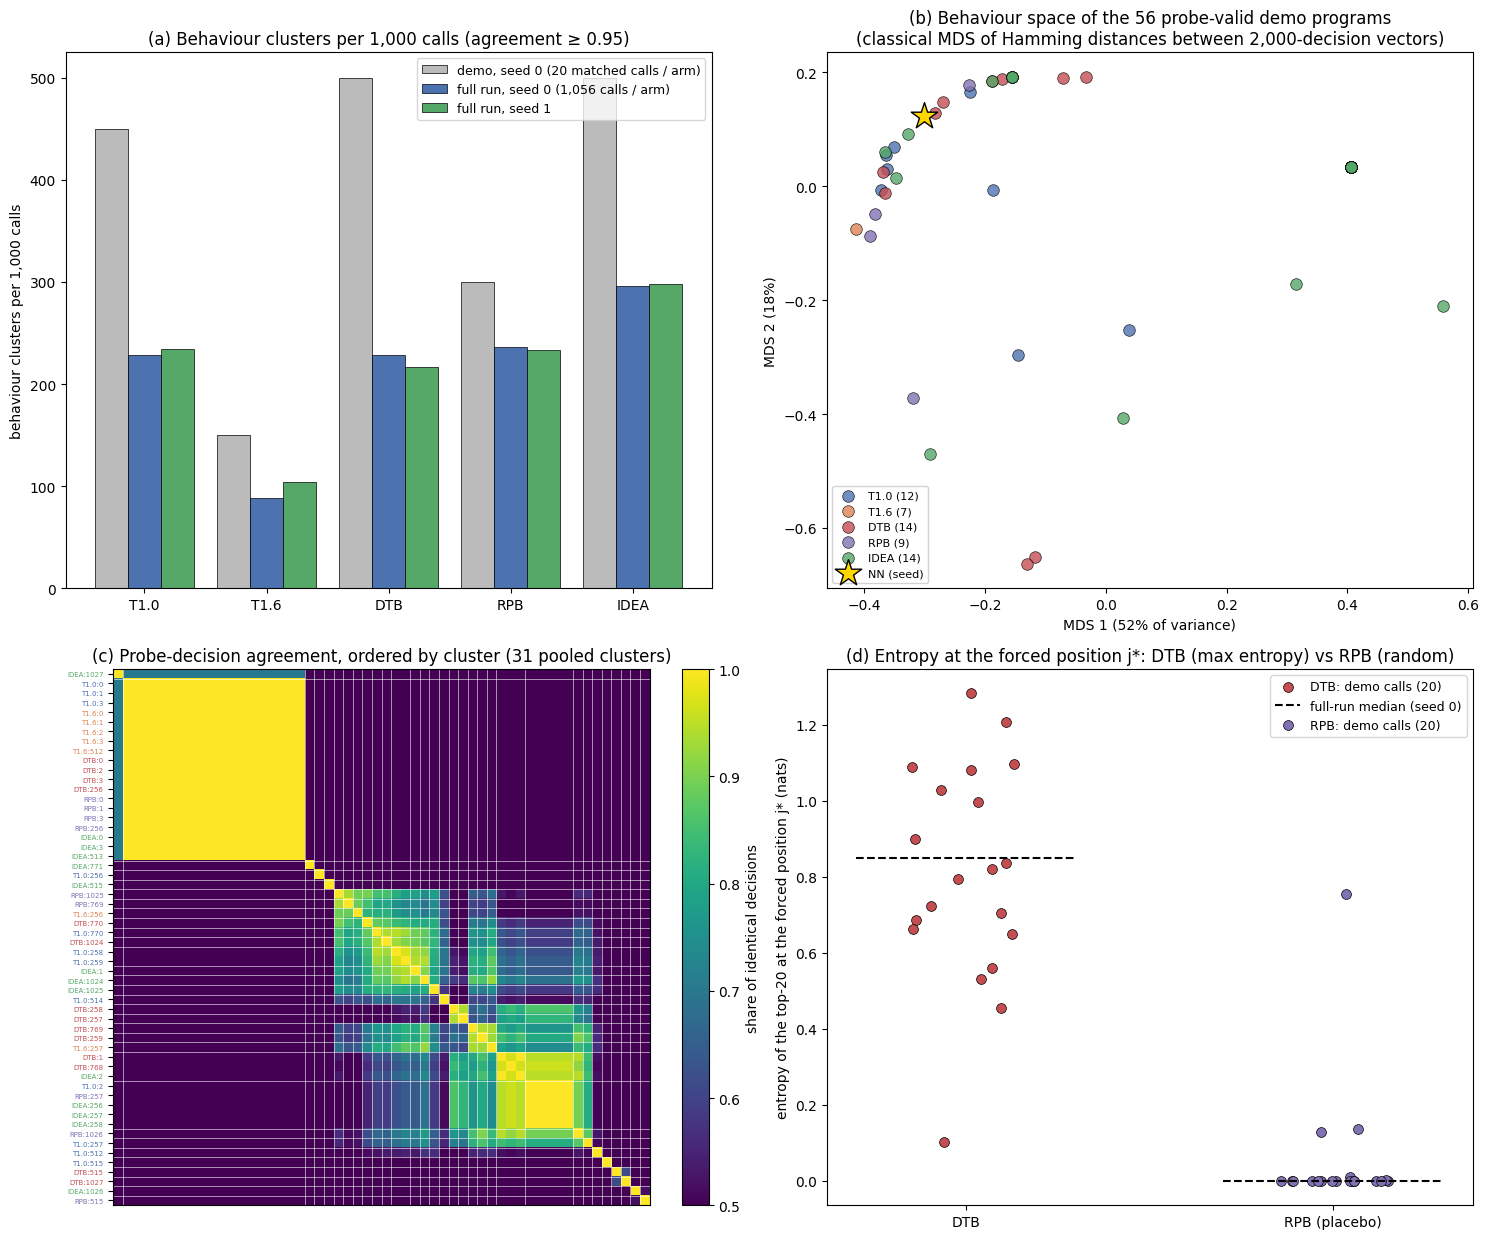

In [28]:
ARM_COLORS = {"T1.0": "#4C72B0", "T1.6": "#DD8452", "DTB": "#C44E52", "RPB": "#8172B3", "IDEA": "#55A868"}
fig, axs = plt.subplots(2, 2, figsize=(15, 12.5))

# (a) clusters per 1,000 calls
ax = axs[0, 0]
xs, w = np.arange(len(ARMS)), 0.27
series = [("demo, seed 0 (20 matched calls / arm)", [cl["per_arm_seed"][f"{x}|0"]["rate_per_1000_calls"] for x in ARMS], "#bbbbbb"),
          ("full run, seed 0 (1,056 calls / arm)", [fr["clusters"][f"{x}|0"]["rate_per_1000_calls"] for x in ARMS], "#4C72B0"),
          ("full run, seed 1", [fr["clusters"][f"{x}|1"]["rate_per_1000_calls"] for x in ARMS], "#55A868")]
for i, (lab_, vals, col) in enumerate(series):
    ax.bar(xs + (i - 1) * w, vals, w, label=lab_, color=col, edgecolor="k", linewidth=0.5)
ax.set_xticks(xs)
ax.set_xticklabels(ARMS)
ax.set_ylabel("behaviour clusters per 1,000 calls")
ax.set_title("(a) Behaviour clusters per 1,000 calls (agreement ≥ 0.95)")
ax.legend(fontsize=9)

# (b) behaviour space: classical MDS of the Hamming distances between decision vectors
pv_rows = [r for r in rows if r.get("probe_valid") and r.get("ast_hash") in dec]
Xb = np.array([dec[r["ast_hash"]] for r in pv_rows] + [nn_dec_logged])
Dh = squareform(pdist(Xb, "hamming"))
n_ = len(Dh)
J = np.eye(n_) - np.ones((n_, n_)) / n_
B = -0.5 * J @ (Dh ** 2) @ J
w_, V_ = np.linalg.eigh(B)
top2 = np.argsort(w_)[::-1][:2]
Y = V_[:, top2] * np.sqrt(np.maximum(w_[top2], 0))
expl = w_[top2] / w_[w_ > 0].sum()
ax = axs[0, 1]
for x in ARMS:
    m_ = [i for i, r in enumerate(pv_rows) if r["arm"] == x]
    ax.scatter(Y[m_, 0], Y[m_, 1], s=70, color=ARM_COLORS[x], label=f"{x} ({len(m_)})", alpha=0.8,
               edgecolor="k", linewidth=0.5)
ax.scatter(Y[-1, 0], Y[-1, 1], marker="*", s=400, color="gold", edgecolor="k", label="NN (seed)", zorder=5)
ax.set_xlabel(f"MDS 1 ({100 * expl[0]:.0f}% of variance)")
ax.set_ylabel(f"MDS 2 ({100 * expl[1]:.0f}%)")
ax.set_title(f"(b) Behaviour space of the {len(pv_rows)} probe-valid demo programs\n"
             "(classical MDS of Hamming distances between 2,000-decision vectors)")
ax.legend(fontsize=8, loc="lower left", framealpha=0.85)

# (c) agreement matrix ordered by complete-linkage cluster
lab_all = cluster_programs(Xb[:-1])["labels"]
order = np.lexsort((np.array([ARMS.index(r["arm"]) for r in pv_rows]), lab_all))
A = 1 - Dh[:-1, :-1][np.ix_(order, order)]
ax = axs[1, 0]
im = ax.imshow(A, vmin=0.5, vmax=1.0, cmap="viridis")
for pos in np.where(np.diff(lab_all[order]) != 0)[0]:
    ax.axhline(pos + 0.5, color="w", lw=0.4)
    ax.axvline(pos + 0.5, color="w", lw=0.4)
ax.set_yticks(range(len(order)))
ax.set_yticklabels([f"{pv_rows[i]['arm']}:{pv_rows[i]['call_idx']}" for i in order], fontsize=5)
for t_, i in zip(ax.get_yticklabels(), order):
    t_.set_color(ARM_COLORS[pv_rows[i]["arm"]])
ax.set_xticks([])
ax.set_title(f"(c) Probe-decision agreement, ordered by cluster ({len(set(lab_all.tolist()))} pooled clusters)")
plt.colorbar(im, ax=ax, fraction=0.046, label="share of identical decisions")

# (d) entropy at the forced position: DTB (argmax entropy) vs RPB (random eligible position)
ax = axs[1, 1]
rng_j = np.random.default_rng(0)
for i, x in enumerate(["DTB", "RPB"]):
    Hs = [b_["H_j_star"] for (a_, _), b_ in BRANCHES.items() if a_ == x and not b_["no_branch"]]
    ax.scatter(i + rng_j.uniform(-0.15, 0.15, len(Hs)), Hs, s=50, color=ARM_COLORS[x], edgecolor="k",
               linewidth=0.5, label=f"{x}: demo calls ({len(Hs)})")
    ax.hlines(fr["dtb_diag"][f"{x}|0"]["H_j_star_median"], i - 0.3, i + 0.3, color="k", linestyle="--",
              label="full-run median (seed 0)" if i == 0 else None)
ax.set_xticks([0, 1])
ax.set_xticklabels(["DTB", "RPB (placebo)"])
ax.set_ylabel("entropy of the top-20 at the forced position j* (nats)")
ax.set_title("(d) Entropy at the forced position j*: DTB (max entropy) vs RPB (random)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

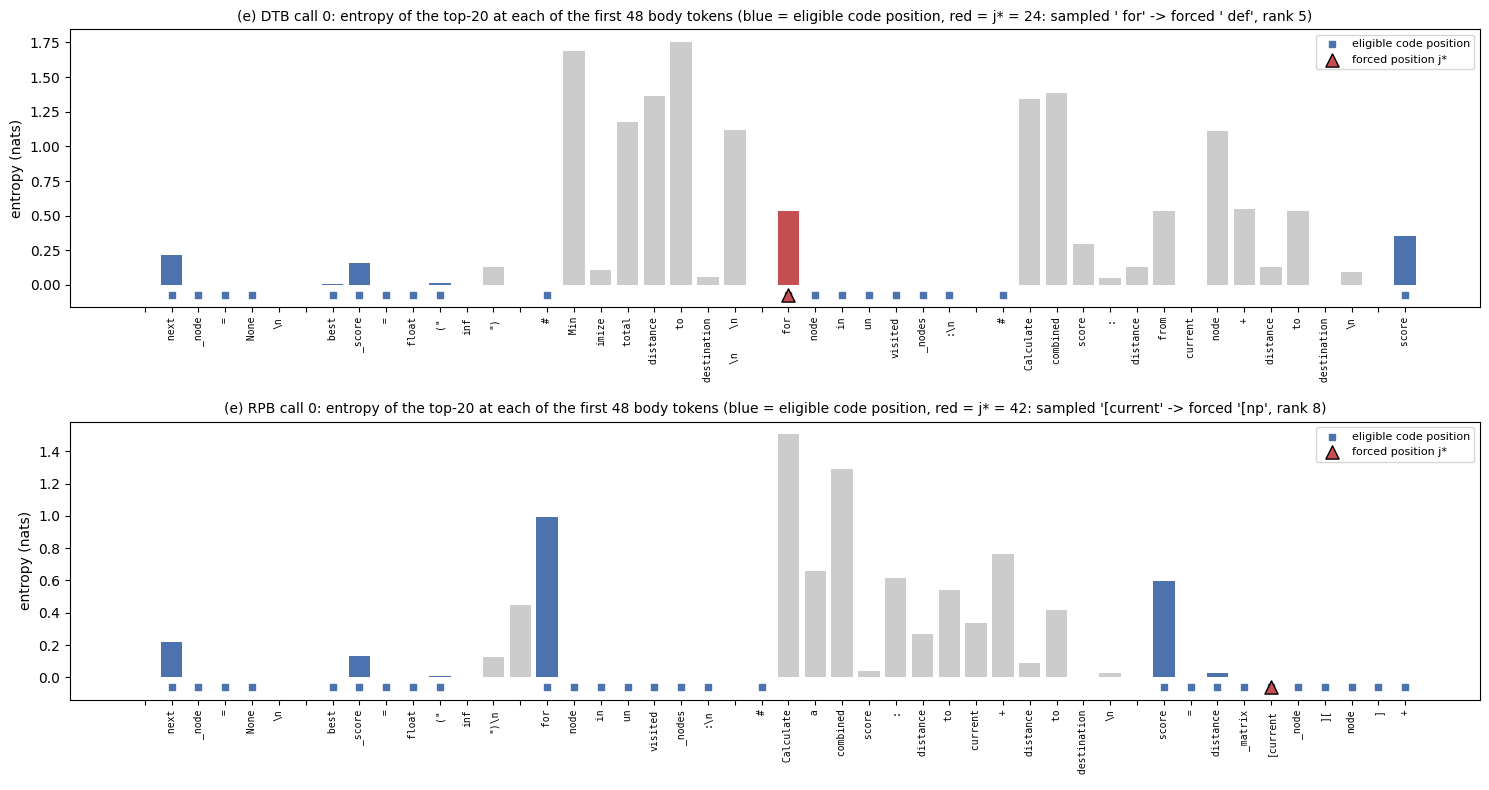

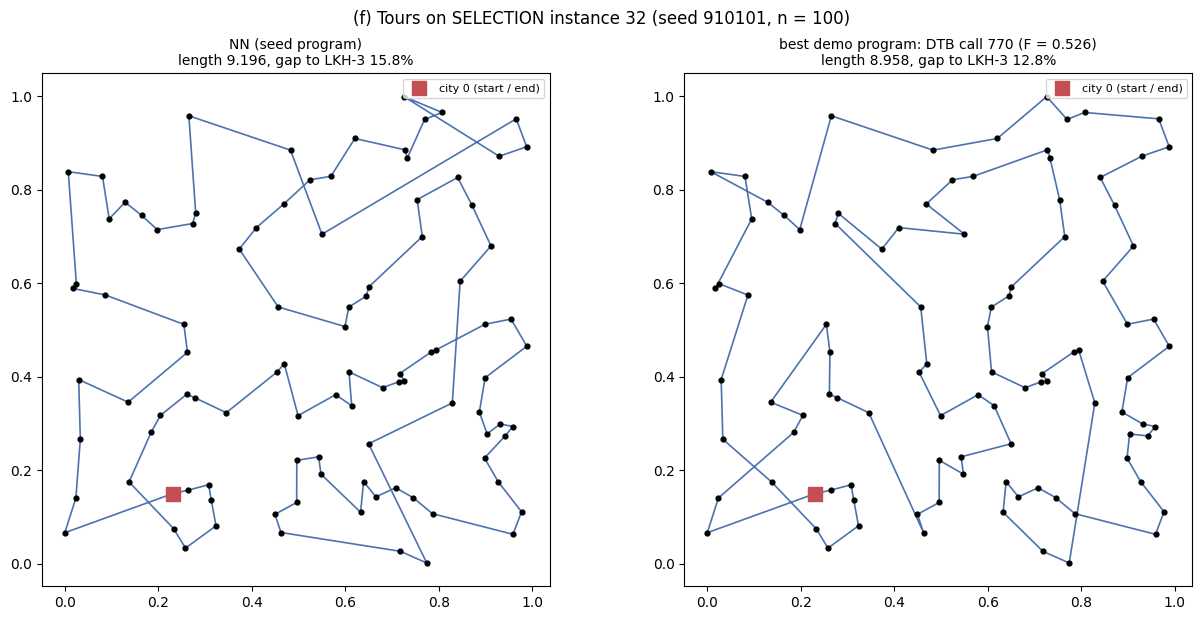

import numpy as np
import math


def select_next_node(current_node, destination_node, unvisited_nodes, distance_matrix):
    """Improved version of select_next_node_v1."""
    next_node = None
    best_score = float("inf")

    for node in unvisited_nodes:
        distance_current_to_node = distance_matrix[current_node][node]
        distance_node_to_destination = distance_matrix[node][destination_node]
        
        # Future cost: shorter distance to destination is better
        # Use inverse of distance squared for faster convergence
        if distance_node_to_destination == 0:
            future_score = 1.0
        else:
            future_score = 1.0 / (1.0 + (distance_node_to_destination ** 2))
        
        # Local cost: distance to nearest unvisited node
        min_distance_to_unvisited = float("inf")
        for candidate in unvisited_nodes:
            if candidate == current_node or candidate == node:
                continue
            candidate_distance = distance

In [29]:
fig, axs = plt.subplots(2, 1, figsize=(15, 8))
for ax, x in zip(axs, ["DTB", "RPB"]):
    cand = [e for e in dtb_calls if e["metadata_arm"] == x and not BRANCHES[(x, e["metadata_call_idx"])]["no_branch"]]
    if not cand:
        ax.set_visible(False)
        continue
    e = cand[0]
    br = BRANCHES[(x, e["metadata_call_idx"])]
    texts, starts, full = token_offsets(tok, e["metadata_r1"]["token_ids"])
    H = [h if h is not None else 0.0 for h in br["H"]]
    cols = ["#C44E52" if j == br["j_star"] else ("#4C72B0" if j in br["eligible"] else "#cccccc") for j in range(len(H))]
    ax.bar(range(len(H)), H, color=cols)
    ax.scatter(br["eligible"], [-0.04 * max(H)] * len(br["eligible"]), marker="s", s=14, color="#4C72B0",
               clip_on=False, label="eligible code position")
    ax.scatter([br["j_star"]], [-0.04 * max(H)], marker="^", s=90, color="#C44E52", edgecolor="k", zorder=5,
               clip_on=False, label="forced position j*")
    ax.legend(loc="upper right", fontsize=8)
    ax.set_xticks(range(len(H)))
    ax.set_xticklabels([repr(t)[1:-1] for t in texts], rotation=90, fontsize=7, family="monospace")
    ax.set_ylabel("entropy (nats)")
    ax.set_title(f"(e) {x} call {e['metadata_call_idx']}: entropy of the top-20 at each of the first {len(H)} body "
                 f"tokens (blue = eligible code position, red = j* = {br['j_star']}: sampled {br['sampled_text']!r}"
                 f" -> forced {br['forced_text']!r}, rank {br['forced_rank']})", fontsize=10)
plt.tight_layout()
plt.show()

# (f) NN's tour vs the best demo program's tour on the first n = 100 SELECTION instance of the demo subset
best_row = min((r for r in rows if r.get("probe_valid") and r.get("F") is not None), key=lambda r: (r["F"], r["call_idx"]))
inst = SEL_IDX[N_SEL_PER_SIZE]
s_, n_i = SETS["selection"][inst]
C = coords_for(s_, n_i)
Dm = dist_matrix(C)
fig, axs = plt.subplots(1, 2, figsize=(13, 6.2))
for ax, (name, code) in zip(axs, [("NN (seed program)", NN_PROGRAM),
                                  (f"best demo program: {best_row['arm']} call {best_row['call_idx']} "
                                   f"(F = {best_row['F']:.3f})", best_row["code"])]):
    res_t = fork_eval(static_check(code), [("selection", "tours", ([Dm], [s_], True))], [SEL_CPU])[0]
    tt = res_t["tours"][0] + [res_t["tours"][0][0]]
    L = res_t["lengths"][0]
    ax.plot(C[tt, 0], C[tt, 1], "-", lw=1.2, color="#4C72B0")
    ax.scatter(C[:, 0], C[:, 1], s=12, color="k", zorder=3)
    ax.scatter(C[0, 0], C[0, 1], s=90, marker="s", color="#C44E52", zorder=4, label="city 0 (start / end)")
    ax.set_title(f"{name}\nlength {L:.3f}, gap to LKH-3 {100 * (L - REFS['selection'][inst]) / REFS['selection'][inst]:.1f}%",
                 fontsize=10)
    ax.set_aspect("equal")
    ax.legend(loc="upper right", fontsize=8)
fig.suptitle(f"(f) Tours on SELECTION instance {inst} (seed {s_}, n = {n_i})")
plt.tight_layout()
plt.show()
print(best_row["code"])

## Notes
**What this demo reproduces exactly.** At full fidelity (32 + 32 SELECTION instances, 2,000 probe states), the
replay reproduces each logged call:
- the request seed, the program sha256 and the AST hash;
- the label, F and the 2,000 probe decisions;
- the DTB/RPB forcing (j\*, candidate set and forced token) from the logged log-probabilities.

NN's gaps and probe decisions also match the run's.

**What differs from the full run.**
- **No LLM calls.** The completions are replayed from the log, because the run needed Qwen3-8B-FP8 on vLLM with a
  GPU.
- **Smaller sample.** The demo uses 100 matched calls of seed 0 instead of 10,812 calls over two seeds, so its
  cluster rates, ratios and verdicts are illustrative. The full-run values are printed next to them.
- **Reference lengths are loaded, not recomputed.** The LKH-3 lengths come from the data rather than from `elkai`.
- **Steps not re-run.** The HELDOUT_EXT and TSPLIB sets, the P1 random search, the published-heuristic corpus,
  the V3-T judges and the stdlib audit (`audit/rederive.py`).
- **Sandbox fixes.** The sandbox runs in-process (a fork from the kernel) instead of in a pool of spawned workers,
  and its address-space budget is added on top of the kernel's size.

**Scaling up.** Set `N_CALLS_PER_ARM = 20`, `N_SEL_PER_SIZE = 32`, `N_PROBE_STATES = 2000` and `N_HELDOUT = 32`
to replay every demo call at full fidelity. The full search itself (`python method.py search`, 10,812 calls) needs
the vLLM server and takes about 2 GPU-hours on an L4.